# Slow features vs accelerometer (all rings)

**Task:** how do the slow features (temperature, humidity, LED levels, LED differences) relate to the accelerometer?

**How to use:** set `DATA_DIR` to the cohort folder (it searches all ring subfolders for `*_labeled_continuous*.xlsx`), then **Run All**. No feature extraction needed.

Per window it computes: mean temperature, humidity, LED1/2/3, LED differences, plus **movement** = std(X)+std(Y)+std(Z) (now, last 5 min, last 15 min) and **hand orientation** = mean X/Y/Z.

In [1]:
# ===== SET THESE =====
DATA_DIR   = "/Users/anishapattanayak/Downloads/3_cohort_01_for_data_analysis"
MAX_DAY    = 10                       # use days 0..MAX_DAY
OUTPUT_DIR = "results"                # tables + plots saved here

In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

SLOW = ["temp_C", "humidity_RH", "LED1_mean", "LED2_mean", "LED3_mean",
        "LED3_minus_LED1", "LED3_minus_LED2", "LED1_minus_LED2"]
ACC = ["move_now", "move_5min", "move_15min", "orient_x", "orient_y", "orient_z"]
LABEL_COLORS = {"relax": "#4caf50", "eustress": "#2196f3", "distress": "#f44336",
                "eustress+distress": "#9c27b0"}


def day_name(fname):
    m = re.search(r"(Ring\d+)_PID_(\d+)_(day\d+_\d+_\d+(?:_\d+)?|baseline)", fname)
    return f"PID{m.group(2)}_{m.group(3)}" if m else Path(fname).stem


def windows_from_file(path):
    d = pd.read_excel(path) if path.suffix == ".xlsx" else pd.read_csv(path)
    d["temp"] = d.TempC_x100 / 100
    d["hum"] = d.HumidityRH_x100 / 100
    for a in ("X", "Y", "Z"):
        d[f"acc{a}"] = d[f"Acc{a}_mg"] / 1000          # mg -> g
    g = d.groupby("Global_Window", sort=True)
    w = pd.DataFrame({
        "Session_ID": g.Session_ID.first(),
        "time": pd.to_datetime(g.RealTime.first()) if "RealTime" in d else pd.NaT,
        "Timestamp_ms": g.Timestamp_ms.first(),
        "n_rows": g.size(),
        "Label": g.Label.first(), "Survey_ID": g.Survey_ID.first(),
        "Period": g.Period.first() if "Period" in d else None,
        "temp_C": g.temp.mean(), "humidity_RH": g.hum.mean(),
        "LED1_mean": g.LED1.mean(), "LED2_mean": g.LED2.mean(), "LED3_mean": g.LED3.mean(),
        "move_now": g.accX.std() + g.accY.std() + g.accZ.std(),
        "orient_x": g.accX.mean(), "orient_y": g.accY.mean(), "orient_z": g.accZ.mean(),
    }).reset_index()
    w["LED3_minus_LED1"] = w.LED3_mean - w.LED1_mean
    w["LED3_minus_LED2"] = w.LED3_mean - w.LED2_mean
    w["LED1_minus_LED2"] = w.LED1_mean - w.LED2_mean
    # keep complete windows only (most common row count = full window)
    w = w[w.n_rows == w.n_rows.mode().iloc[0]].copy()
    # movement over the last 5 / 15 minutes (within the same session, by real time)
    if w.time.notna().all():
        w = w.sort_values(["Session_ID", "time"])
        parts = []
        for _, s in w.groupby("Session_ID"):
            s = s.set_index("time")
            s["move_5min"] = s.move_now.rolling("5min").mean()
            s["move_15min"] = s.move_now.rolling("15min").mean()
            parts.append(s.reset_index())
        w = pd.concat(parts)
    else:
        w["move_5min"] = w.move_now.rolling(15, min_periods=1).mean()
        w["move_15min"] = w.move_now.rolling(45, min_periods=1).mean()
    w["day"] = day_name(path.name)
    return w.reset_index(drop=True)


def eta2(x, groups):
    x = pd.Series(np.asarray(x, float)); groups = pd.Series(np.asarray(groups))
    ok = x.notna(); x, groups = x[ok], groups[ok]
    tot = ((x - x.mean()) ** 2).sum()
    if tot == 0 or groups.nunique() < 2:
        return np.nan
    return float(sum(len(v) * (v.mean() - x.mean()) ** 2 for _, v in x.groupby(groups.values)) / tot)


def r2_from_acc(df, feat):
    s = df[[feat] + ACC].dropna()
    if len(s) < 10:
        return np.nan
    X = np.column_stack([np.ones(len(s)), s[ACC].to_numpy()])
    y = s[feat].to_numpy()
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ beta
    return float(1 - (res ** 2).sum() / ((y - y.mean()) ** 2).sum())


def corr_table(df):
    rows = []
    for f in SLOW:
        r = {"feature": f}
        for a in ACC:
            s = df[[f, a]].dropna()
            r[f"rho_{a}"] = spearmanr(s[f], s[a]).correlation if len(s) > 5 else np.nan
        rows.append(r)
    return pd.DataFrame(rows)


def plot_day(w, out_png):
    w = w.sort_values("time" if w.time.notna().all() else "Timestamp_ms")
    t = w.time if w.time.notna().all() else w.Timestamp_ms / 60000
    panels = [("temp_C", "Temp (C)"), ("humidity_RH", "Humidity (%RH)"),
              (["LED3_minus_LED1", "LED3_minus_LED2", "LED1_minus_LED2"], "LED differences"),
              ("move_now", "Movement (g)")]
    fig, axes = plt.subplots(len(panels), 1, figsize=(12, 9), sharex=True)
    for ax, (cols, title) in zip(axes, panels):
        for c in (cols if isinstance(cols, list) else [cols]):
            ax.plot(t, w[c], ".", ms=2, label=c)
        if cols == "move_now":
            ax.plot(t, w.move_15min, "-", lw=1.2, color="k", label="last 15 min")
        ax.set_ylabel(title, fontsize=9)
        ax.legend(fontsize=7, loc="upper right")
        # label colour strip at the bottom of each panel
        lo, hi = ax.get_ylim()
        ax.scatter(t, np.full(len(w), lo), c=w.Label.map(LABEL_COLORS).fillna("#999"), s=6, marker="s")
    axes[0].set_title(f"{w.day.iloc[0]}  (squares at the bottom = label: green relax, blue eustress, "
                      "red distress, purple eustress+distress)", fontsize=9)
    fig.tight_layout(); fig.savefig(out_png, dpi=110); plt.show()




## 1. Load all rings and build one row per window

In [3]:
out = Path(OUTPUT_DIR); (out / "plots").mkdir(parents=True, exist_ok=True)
day_of = lambda n: int(re.search(r"_day(\d+)_", n).group(1))
files = sorted(f for f in Path(DATA_DIR).rglob("*labeled_continuous*.xlsx")
               if not f.name.startswith("~$") and day_of(f.name) <= MAX_DAY)
assert files, f"No *labeled_continuous*.xlsx files in {DATA_DIR}"
parts = []
for f in files:
    w = windows_from_file(f)
    w["PID"] = "PID" + re.search(r"PID_(\d+)", f.name).group(1)
    w["daynum"] = day_of(f.name)
    w["date"] = (re.search(r"_day\d+_(\d+_\d+_\d+)", f.name) or [None, ""])[1]
    parts.append(w)
# same day number twice for one ring (e.g. PID101 day5 10_21) -> the later date becomes the next day
for pid in {w.PID.iloc[0] for w in parts}:
    seen = set()
    for w in sorted([w for w in parts if w.PID.iloc[0] == pid], key=lambda w: (w.daynum.iloc[0], w.date.iloc[0])):
        d = w.daynum.iloc[0]
        while d in seen: d += 1
        seen.add(d); w["daynum"] = d
for w in parts:
    w["day"] = f"{w.PID.iloc[0]}_day{w.daynum.iloc[0]:02d}"
df = pd.concat(parts, ignore_index=True)
df.to_csv(out / "per_window_slow_features.csv", index=False)
print(f"{len(df)} windows, {df.day.nunique()} days")
display(pd.crosstab(df.PID, df.Label, margins=True))

13757 windows, 29 days


Label,distress,eustress,eustress+distress,relax,All
PID,,,,,
PID101,1202,882,1209,1712,5005
PID102,274,532,2389,403,3598
PID104,25,25,1766,3338,5154
All,1501,1439,5364,5453,13757


## 2. Basic check: ranges per ring
Humidity at 99-100% most of the time means the sensor is saturated (not useful).

In [4]:
rng = df.groupby("PID")[["temp_C", "humidity_RH", "LED1_mean", "LED2_mean", "LED3_mean", "move_now"]].median().round(2)
rng["humidity_at_99plus_%"] = df.groupby("PID").humidity_RH.apply(lambda s: round(100 * (s >= 99).mean()))
display(rng)

,temp_C,humidity_RH,LED1_mean,LED2_mean,LED3_mean,move_now,humidity_at_99plus_%
PID,,,,,,,
PID101,31.18,100.69,163185.39,265824.00,108594.88,0.36,79
PID102,29.24,90.65,187251.86,320332.05,108073.33,0.07,1
PID104,27.84,92.35,160588.76,405981.44,105064.39,0.06,0


## 3. Time series per day
Squares at the bottom = label (green relax, blue eustress, red distress, purple eustress+distress).

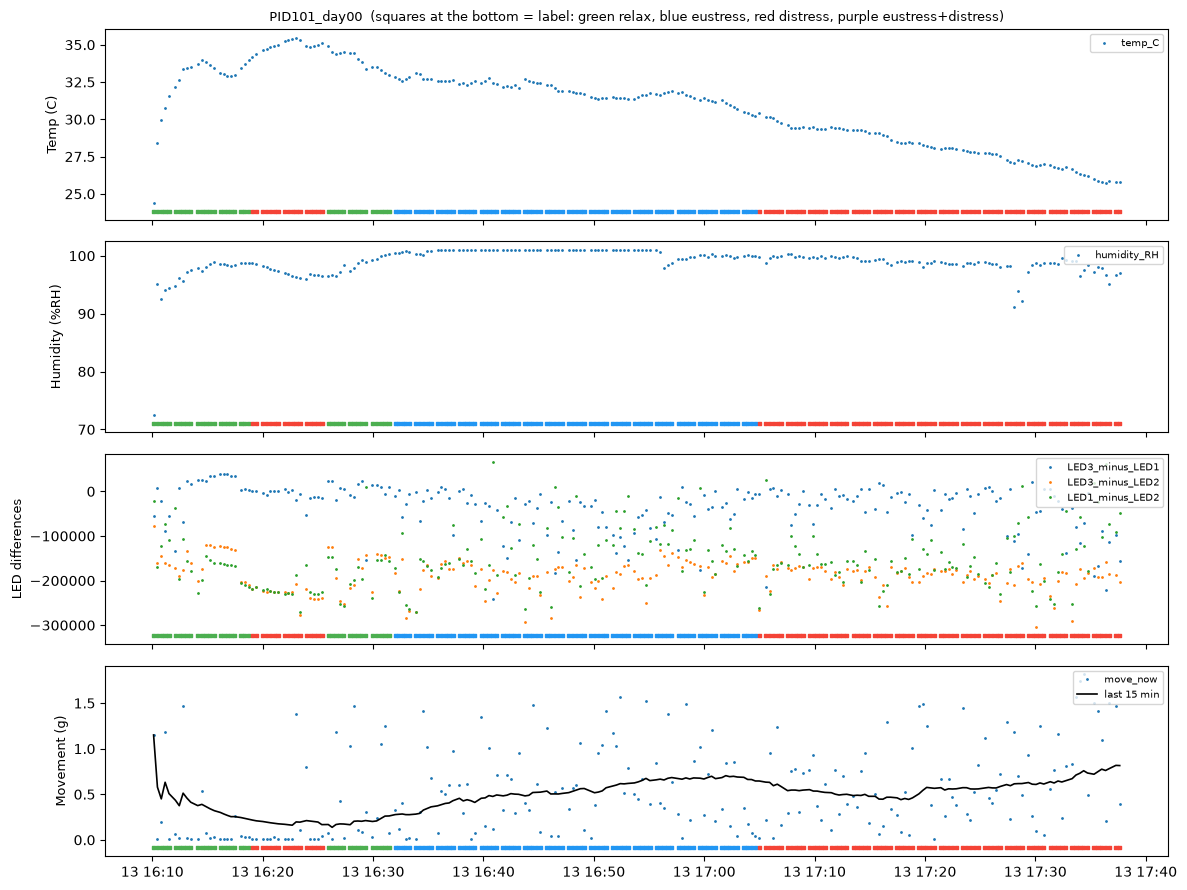

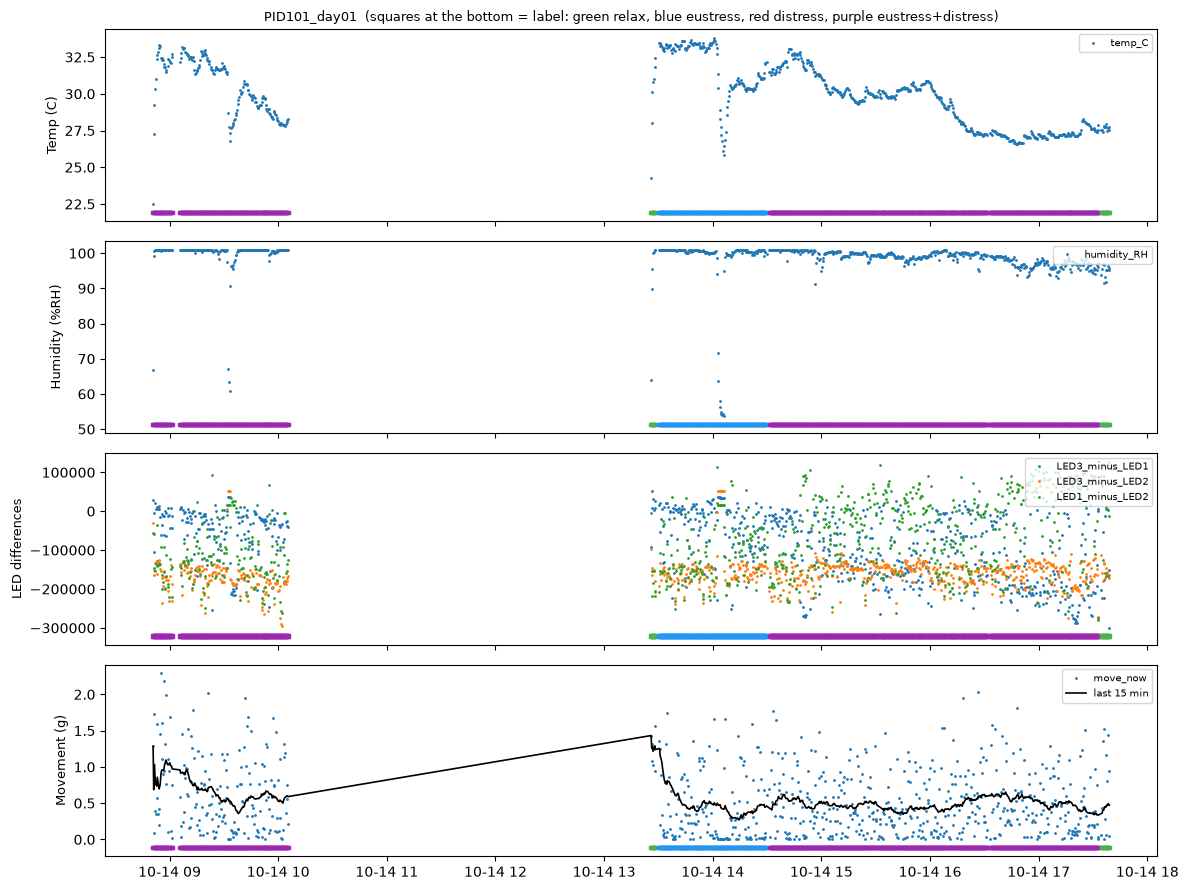

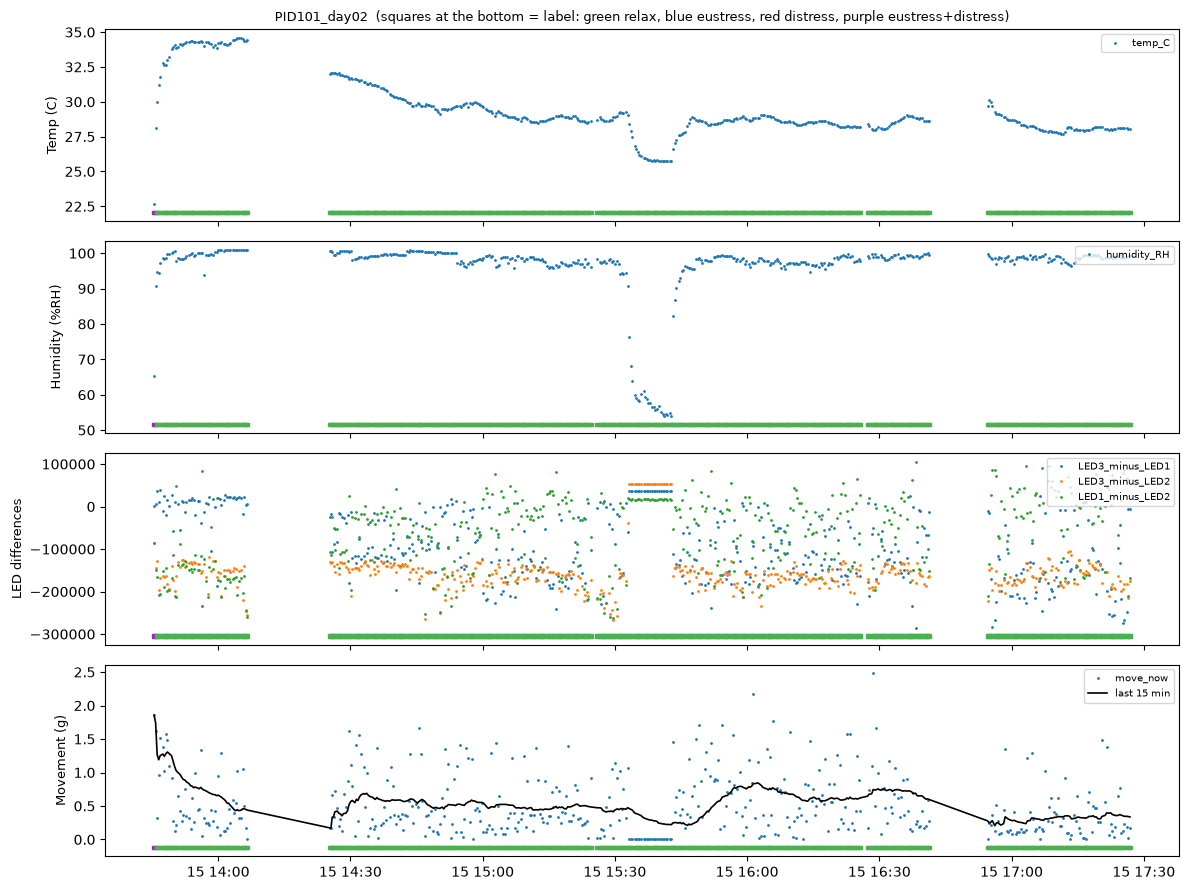

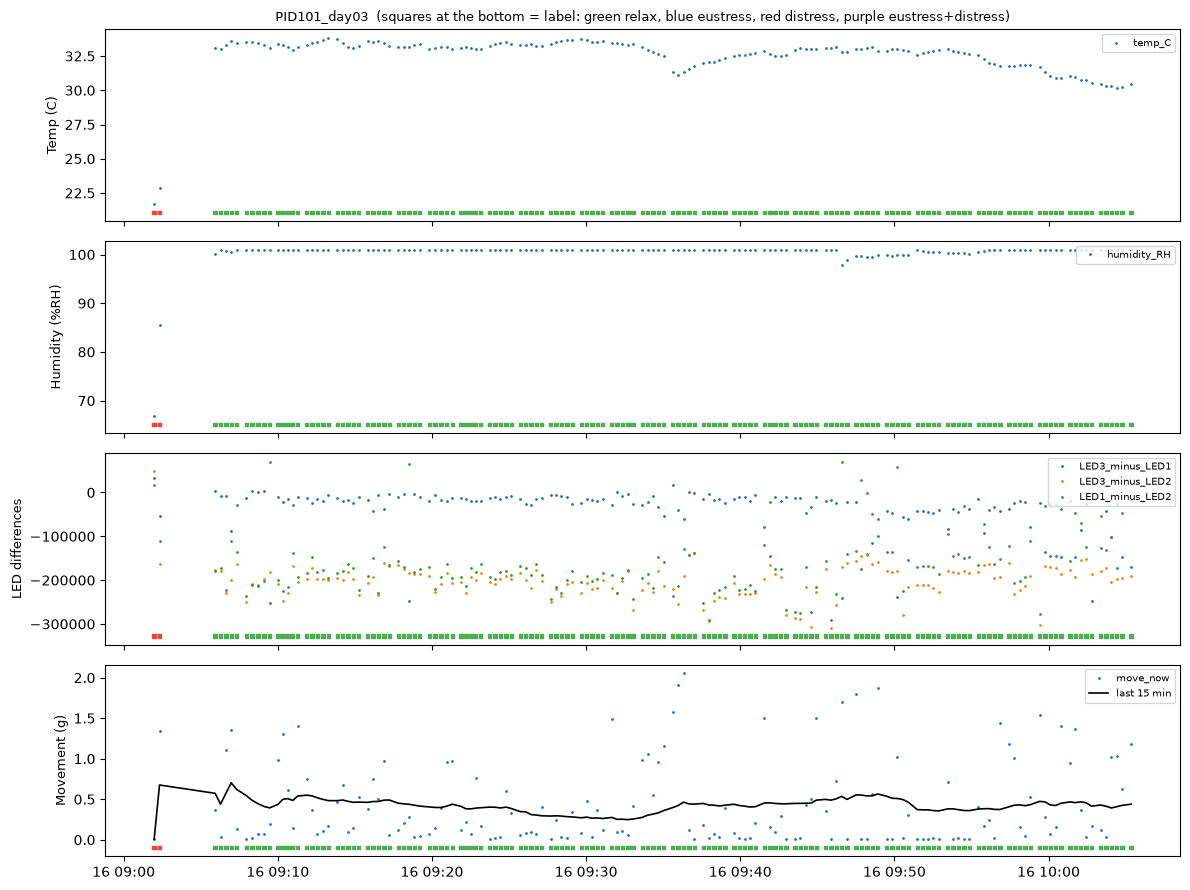

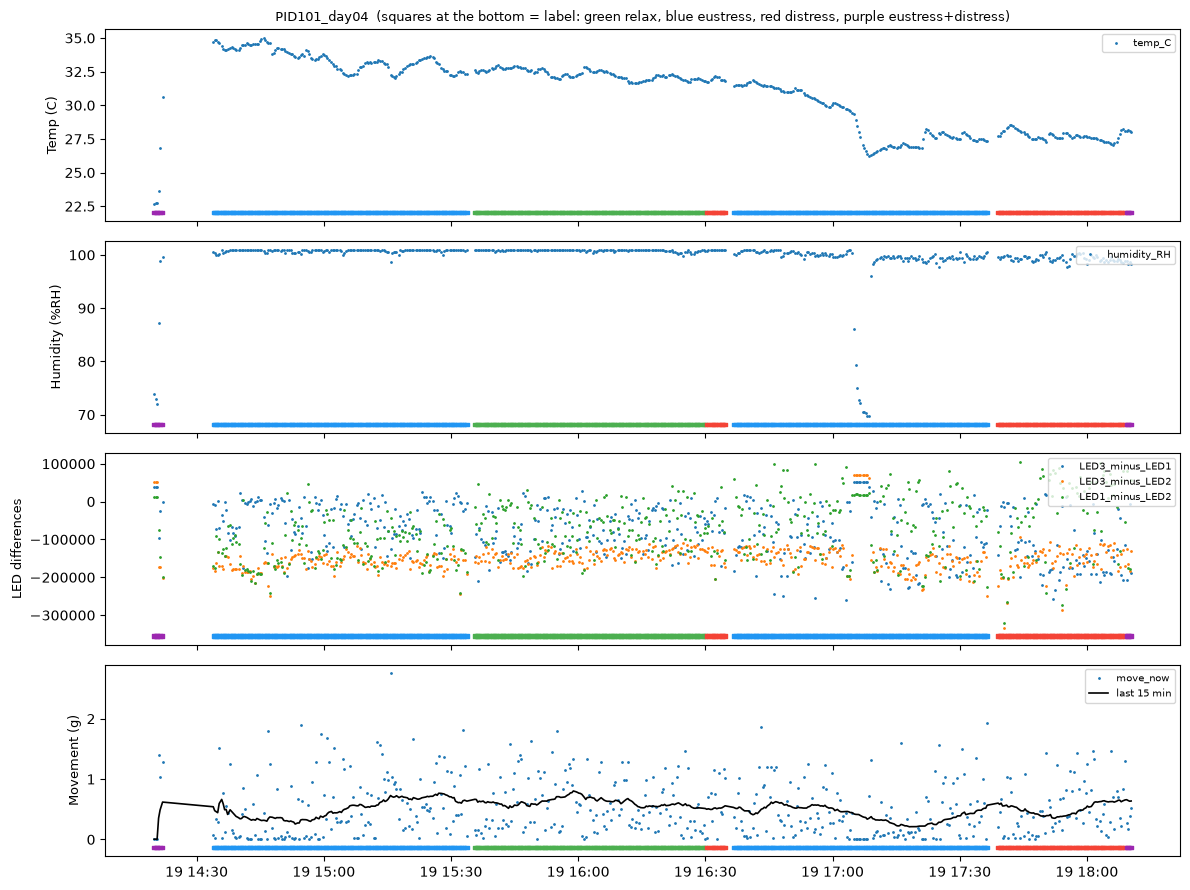

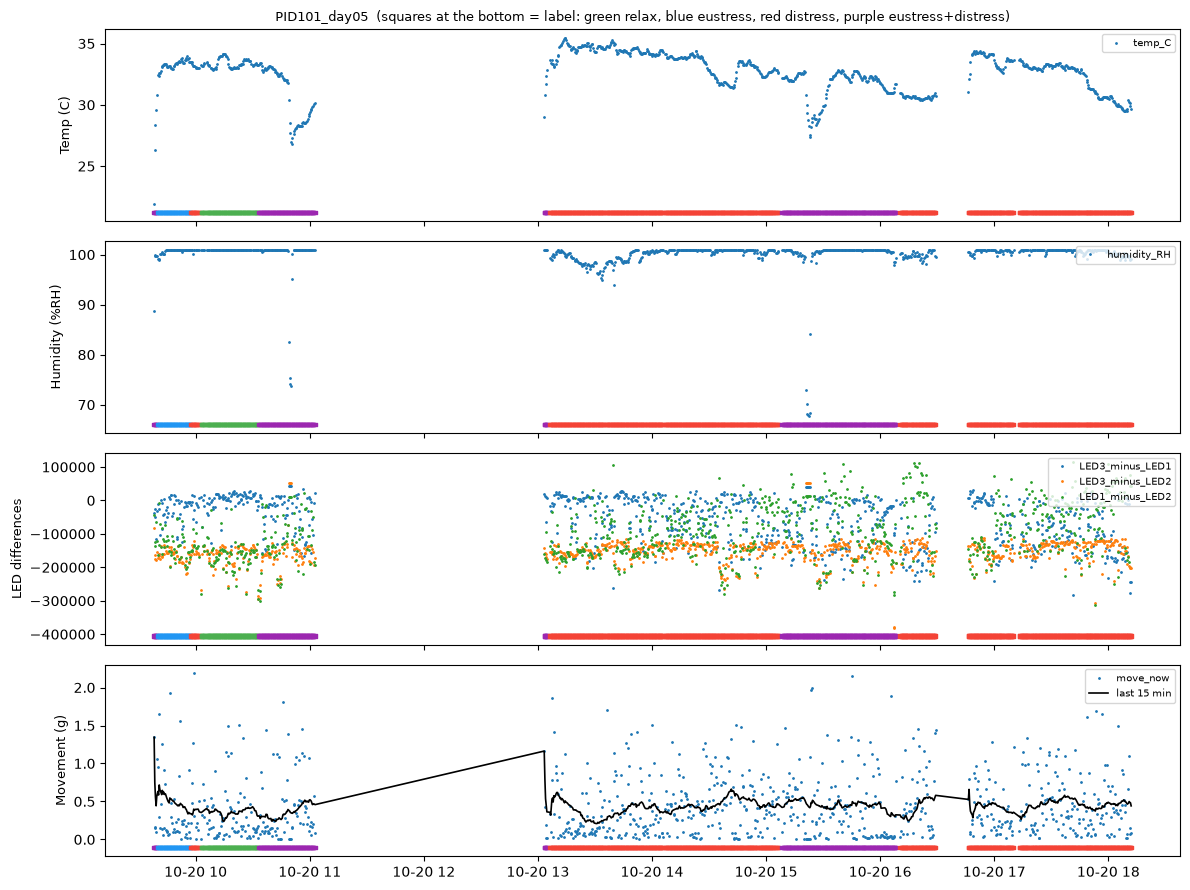

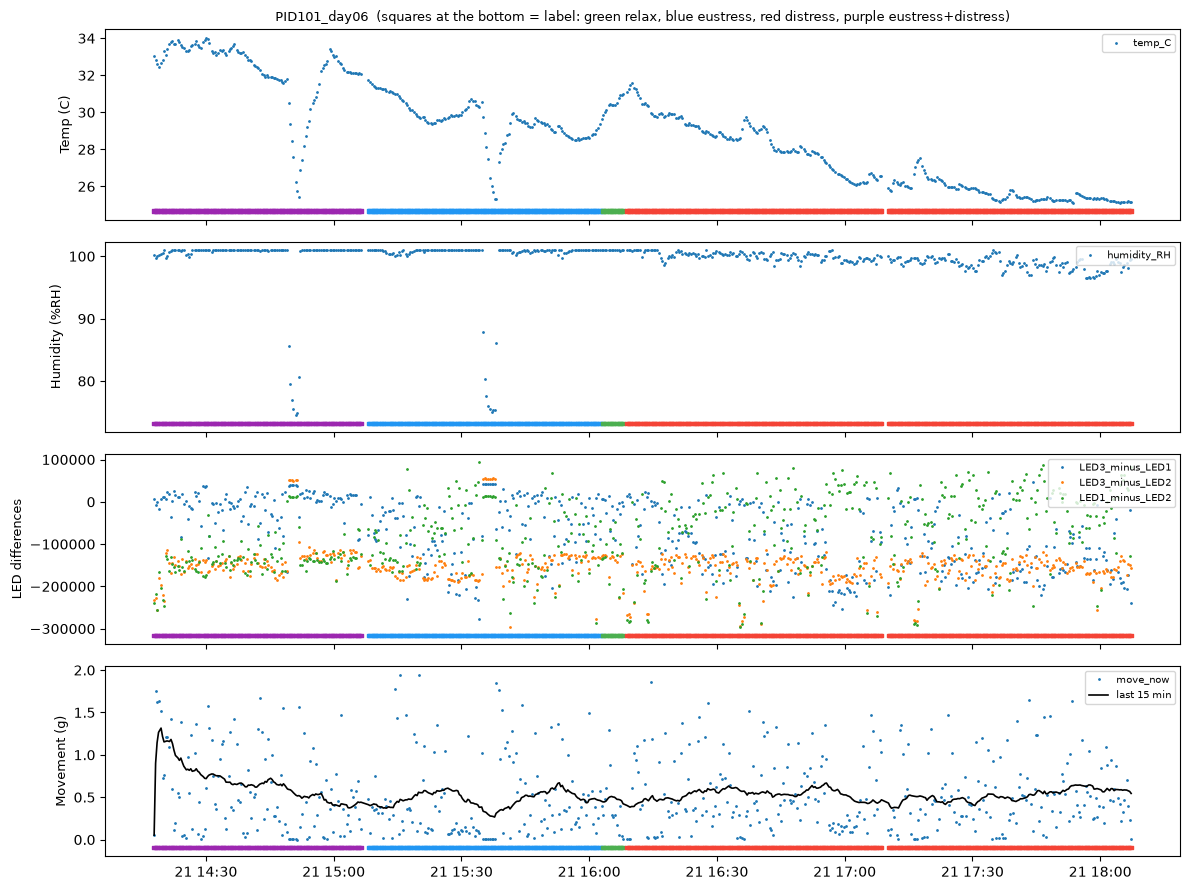

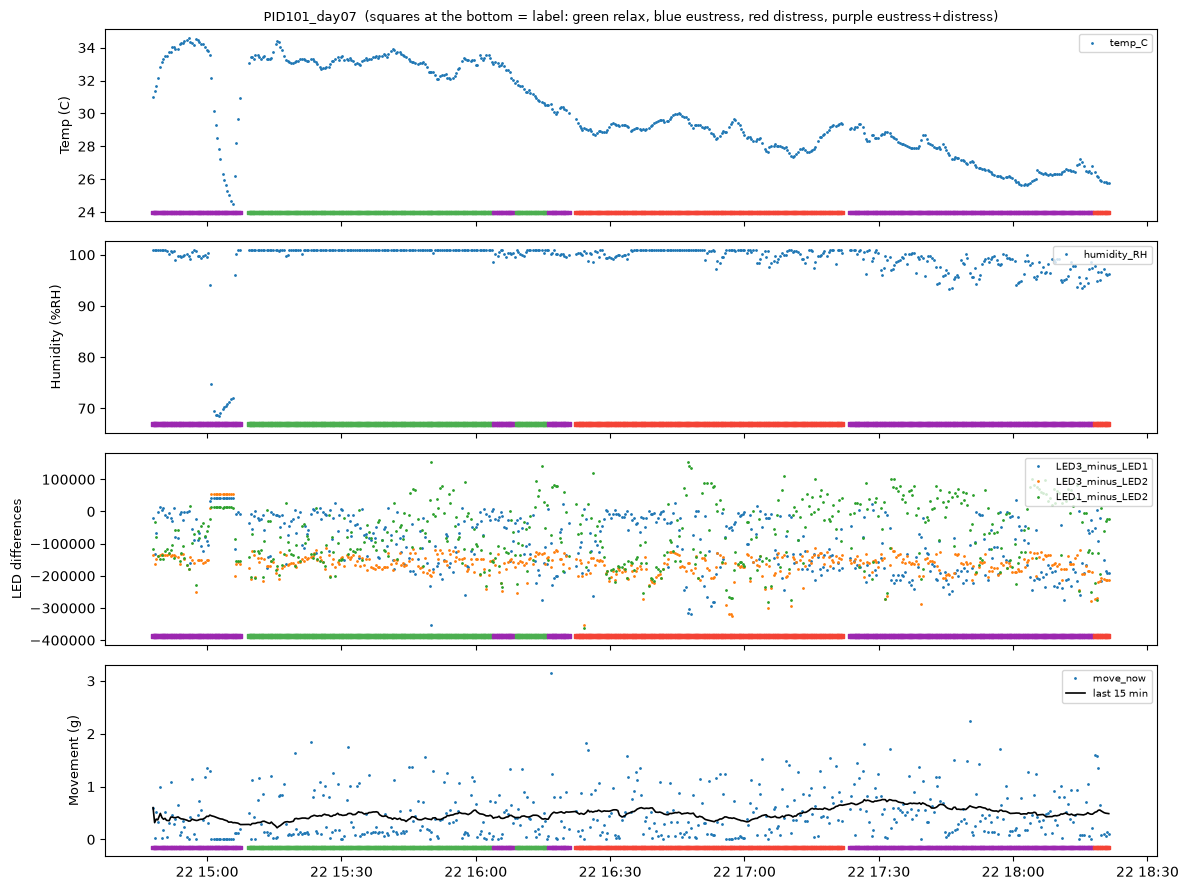

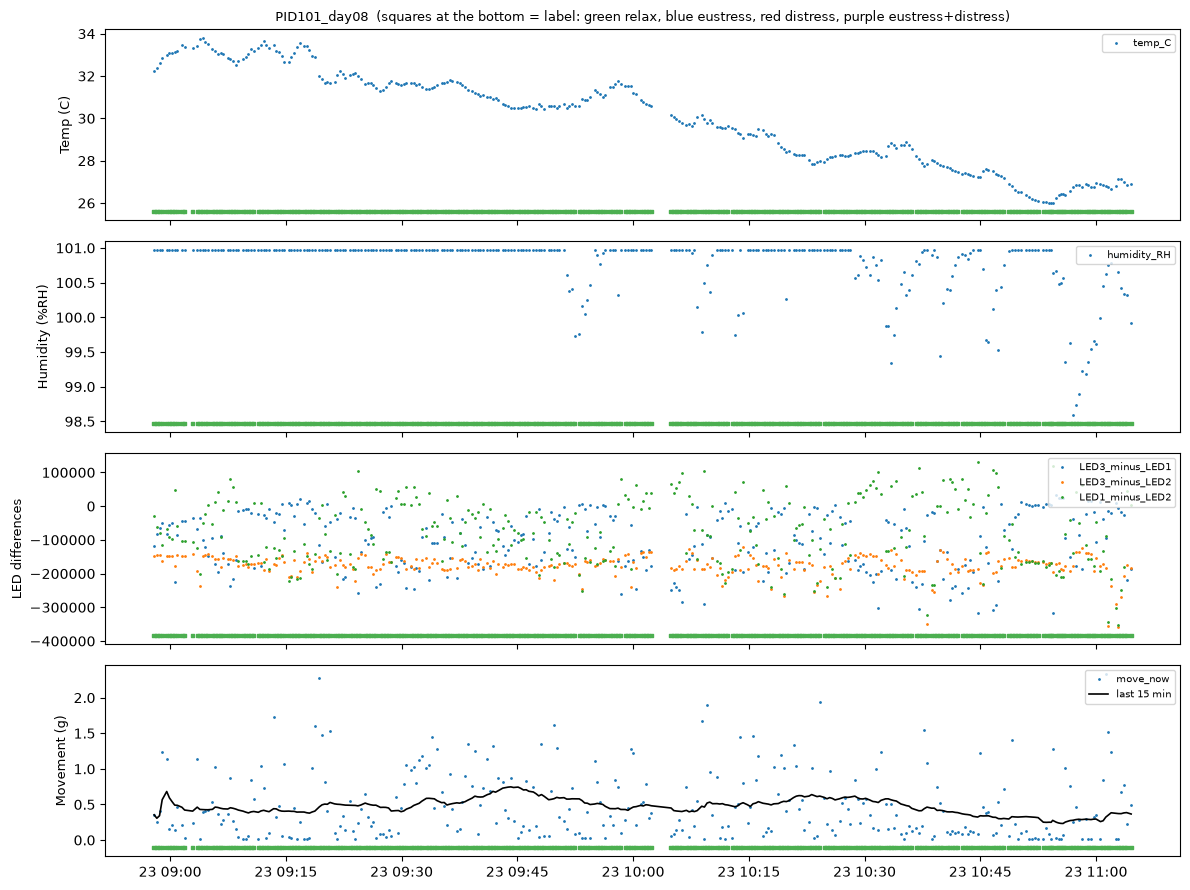

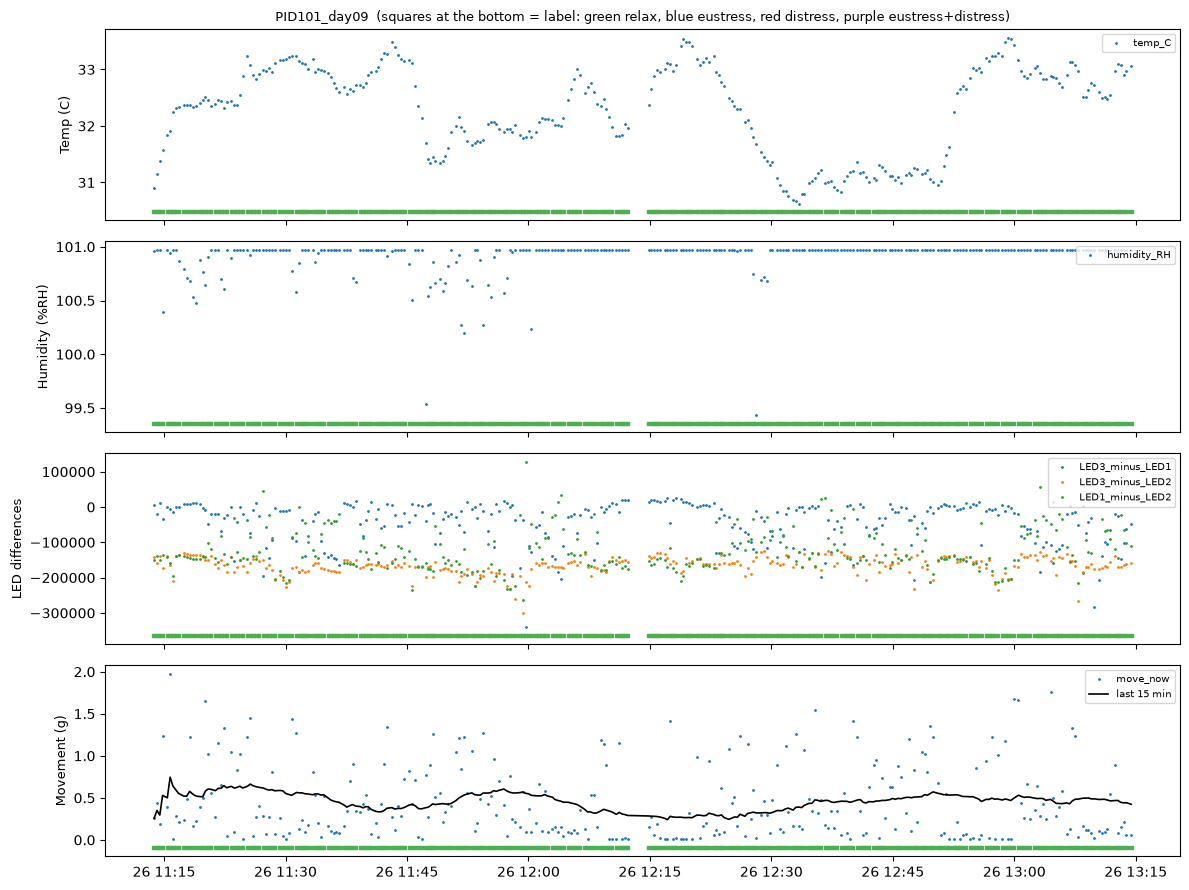

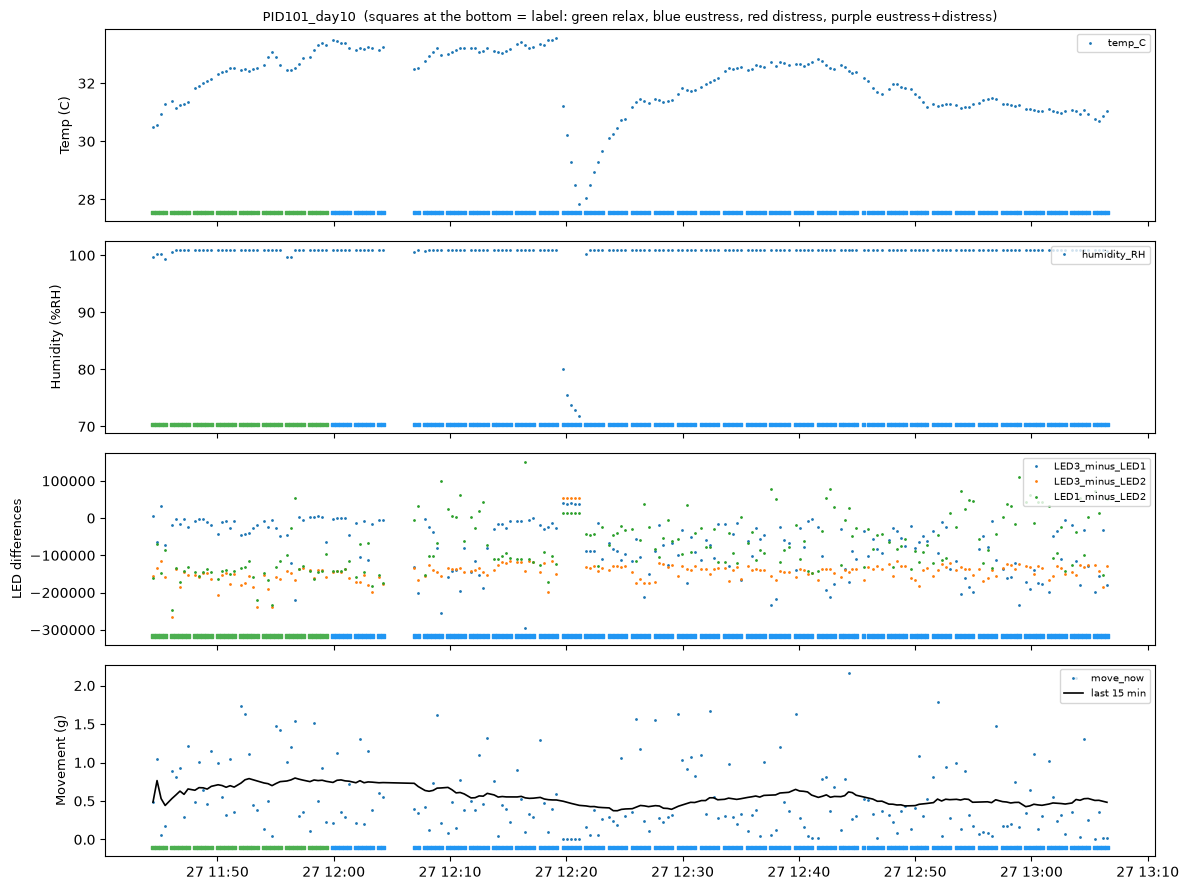

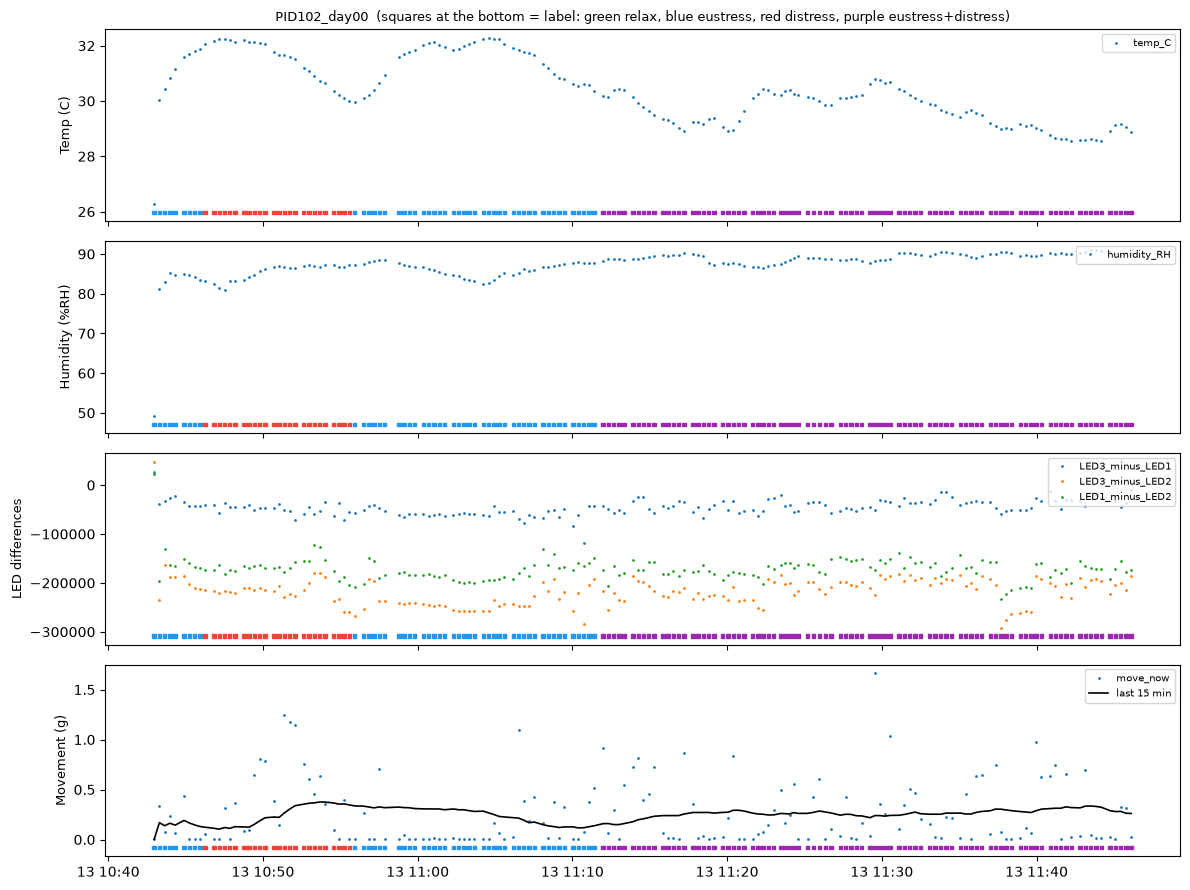

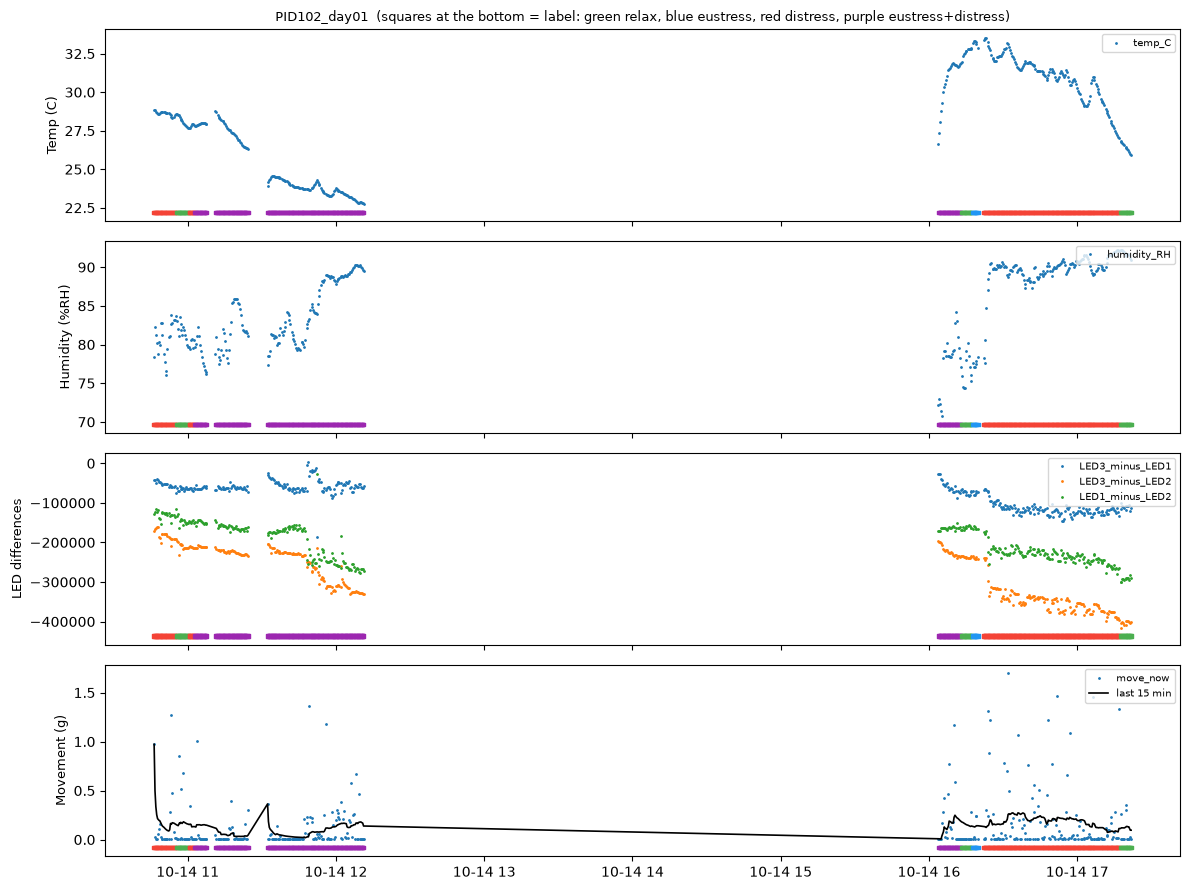

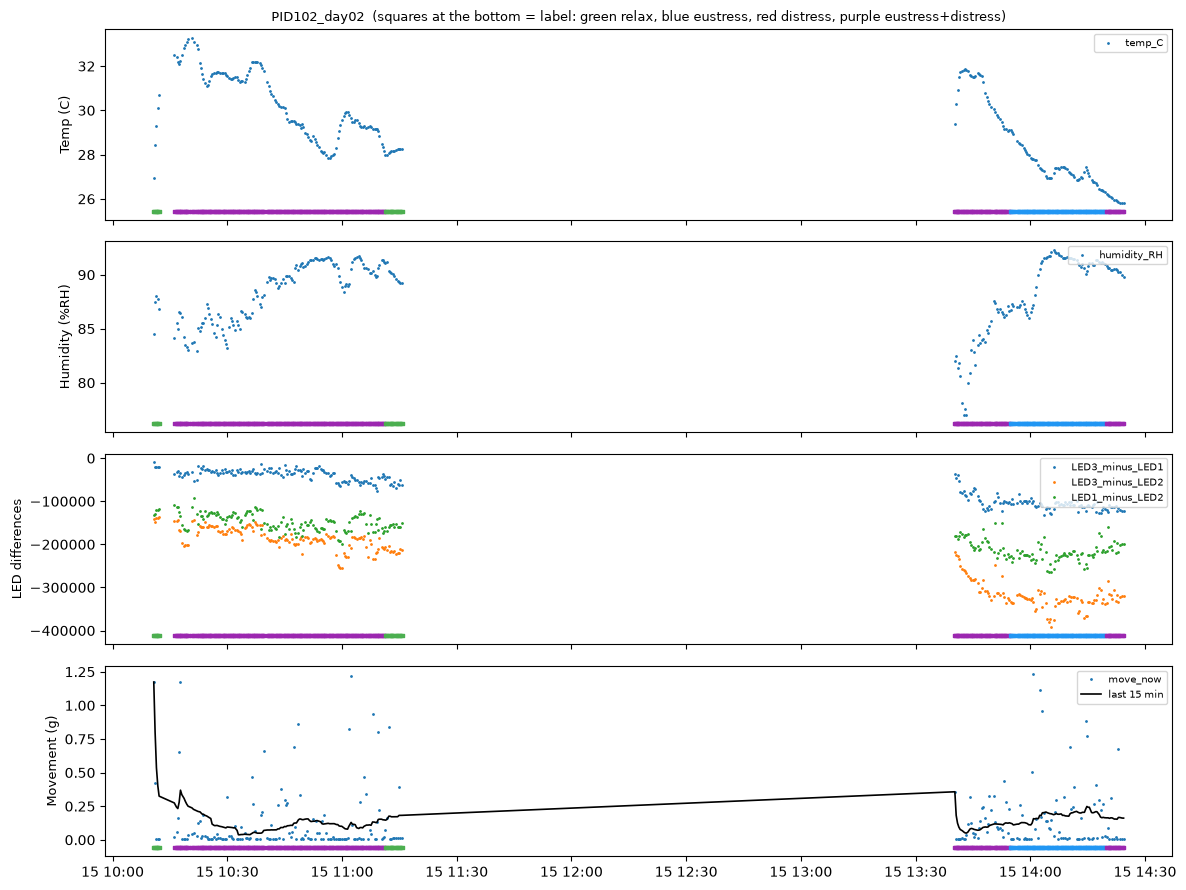

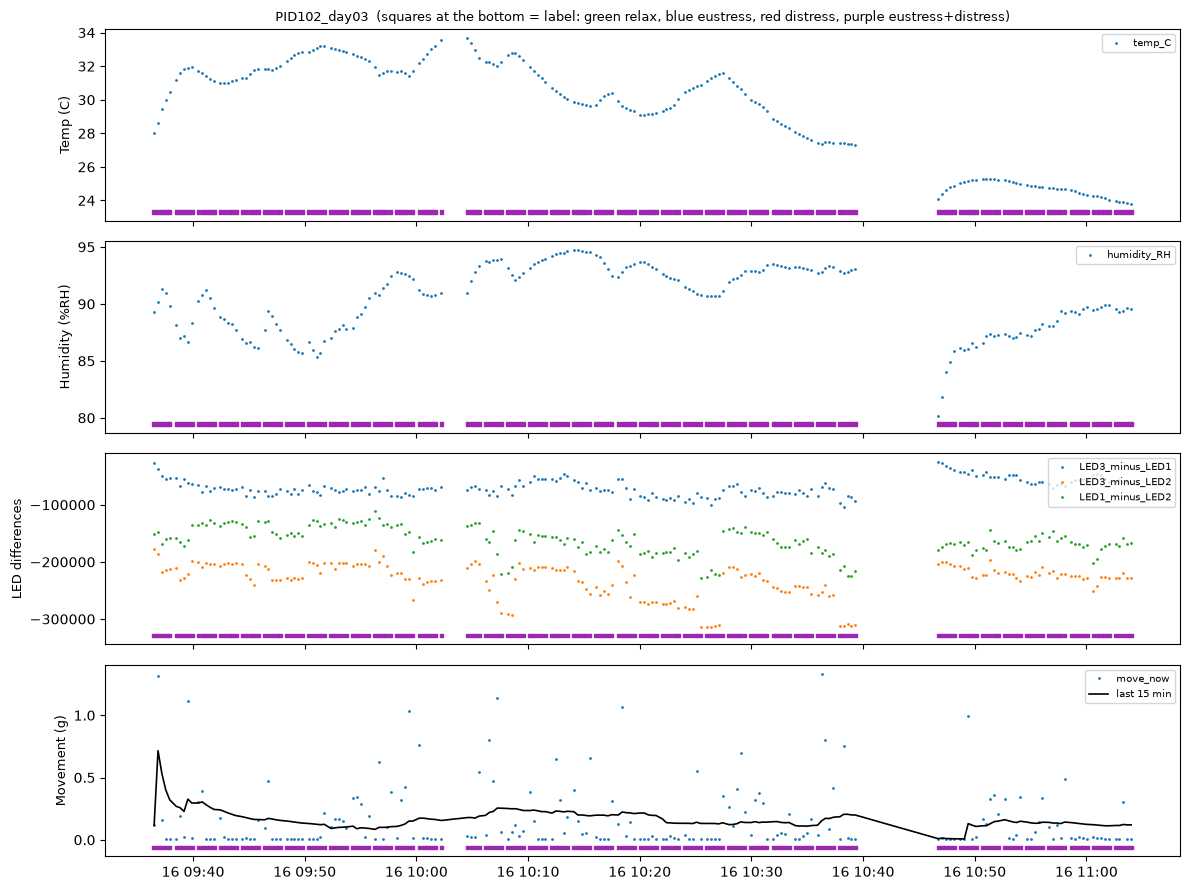

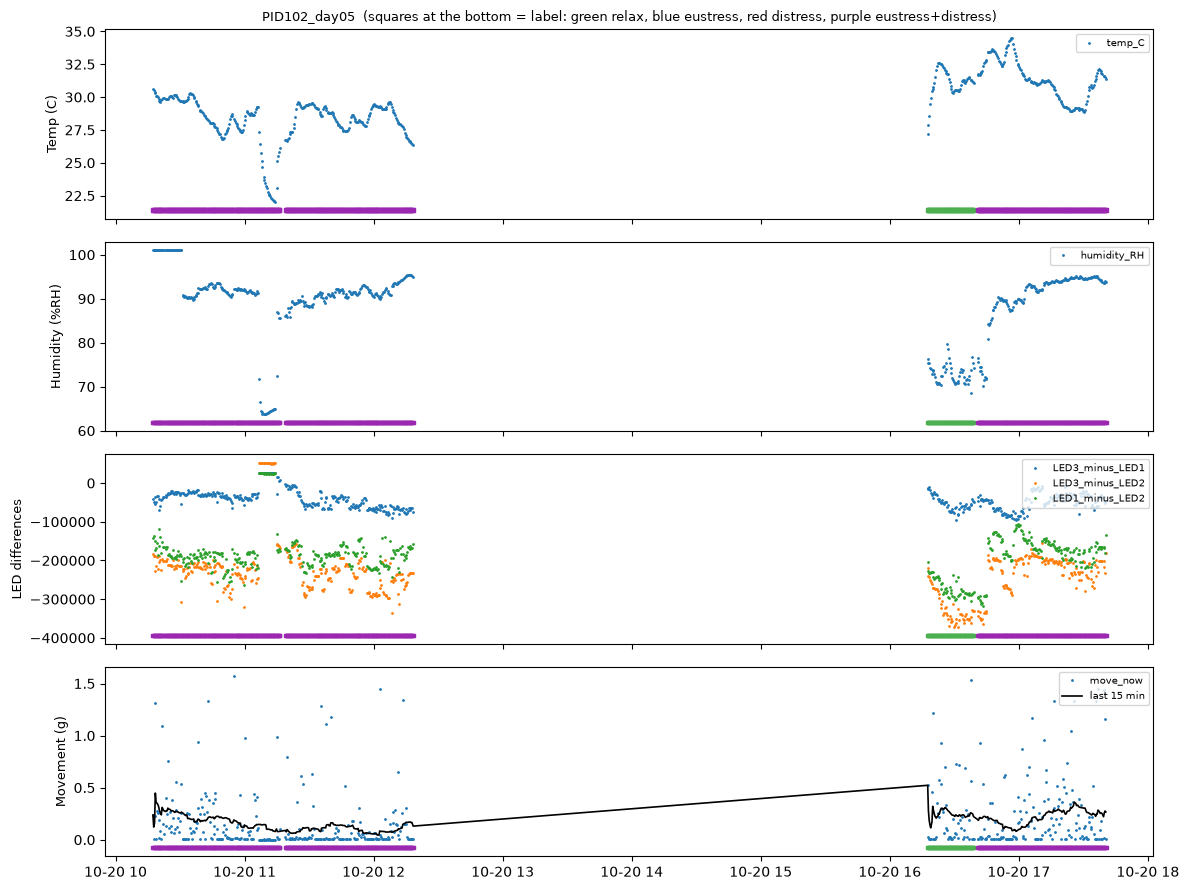

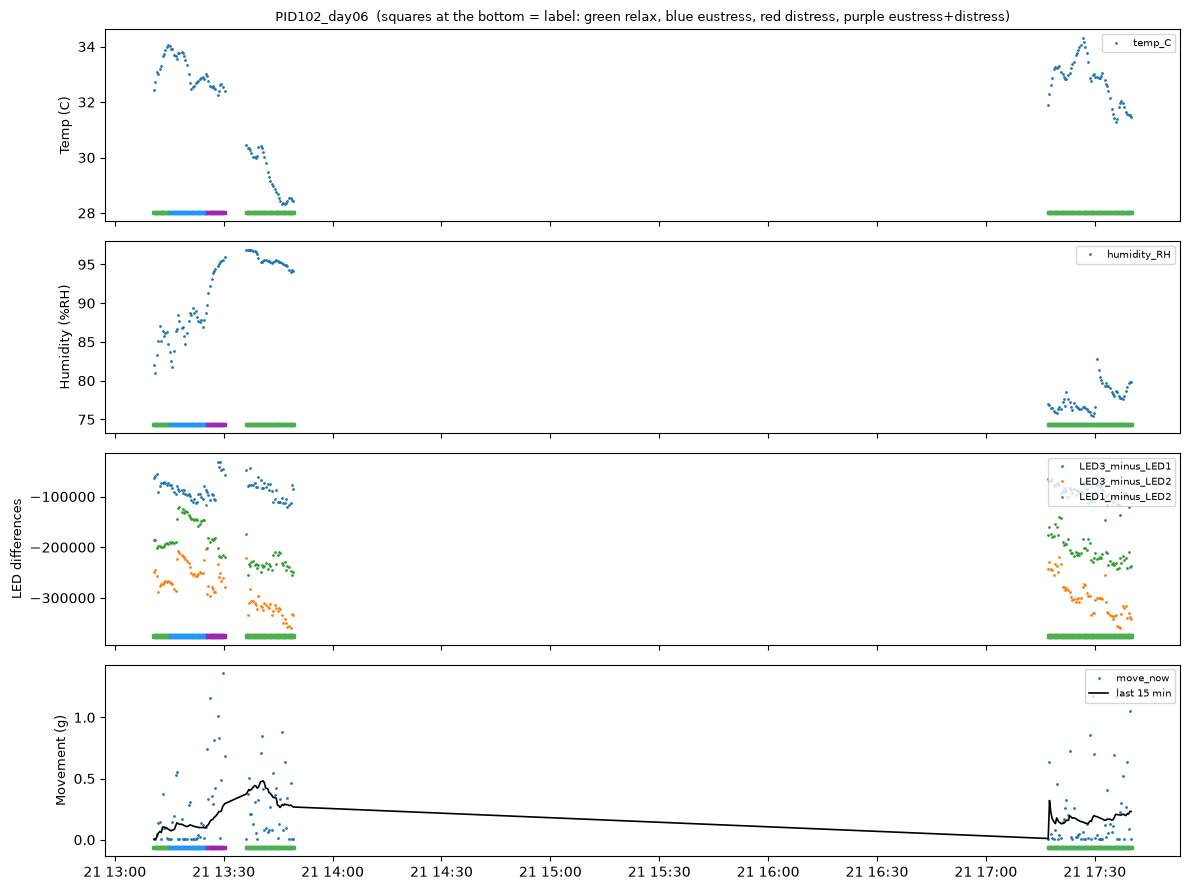

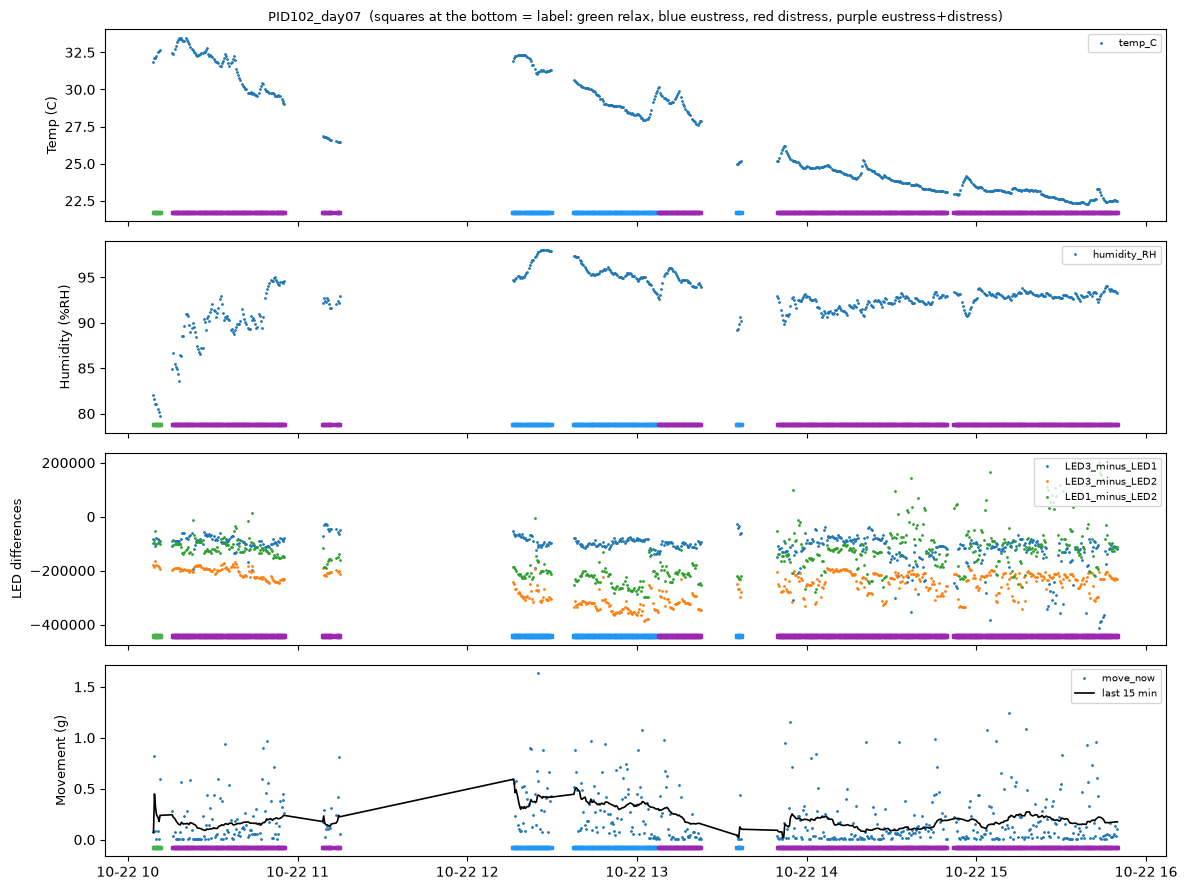

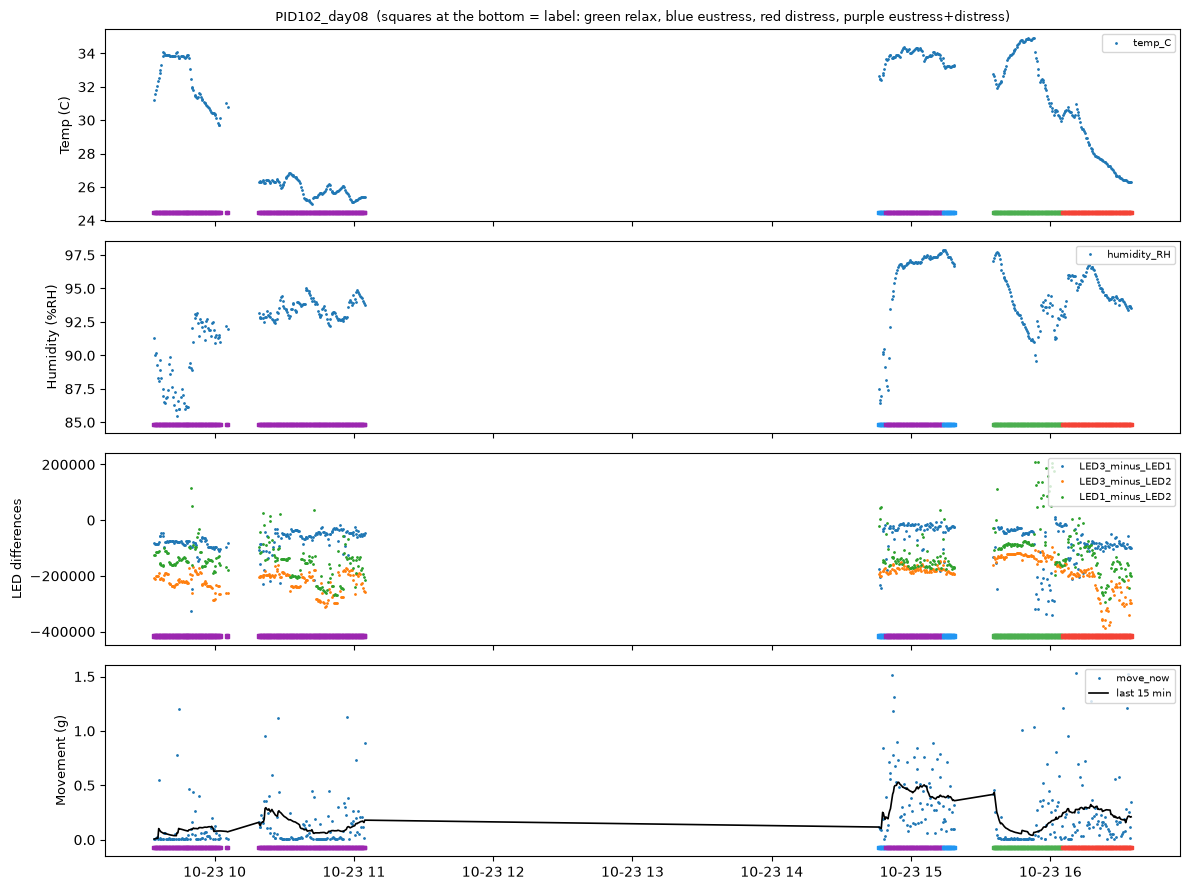

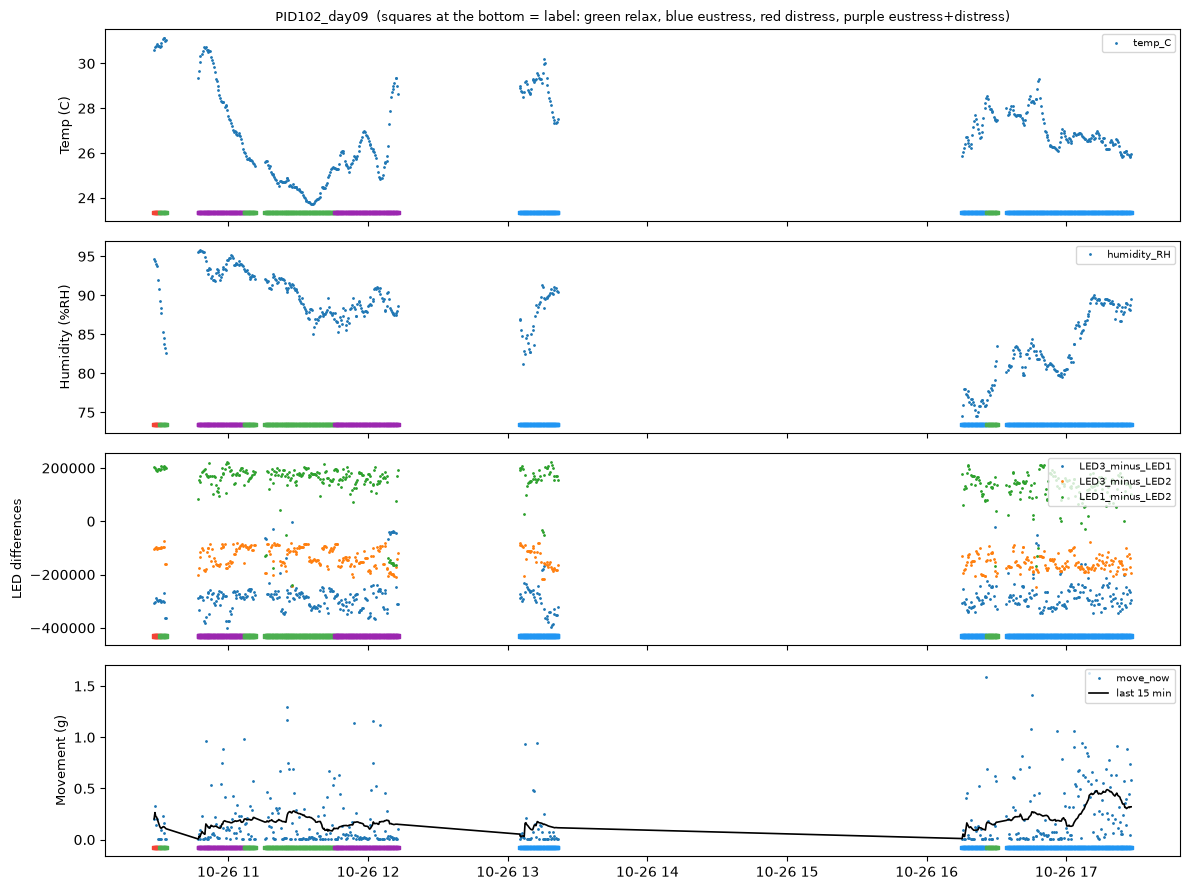

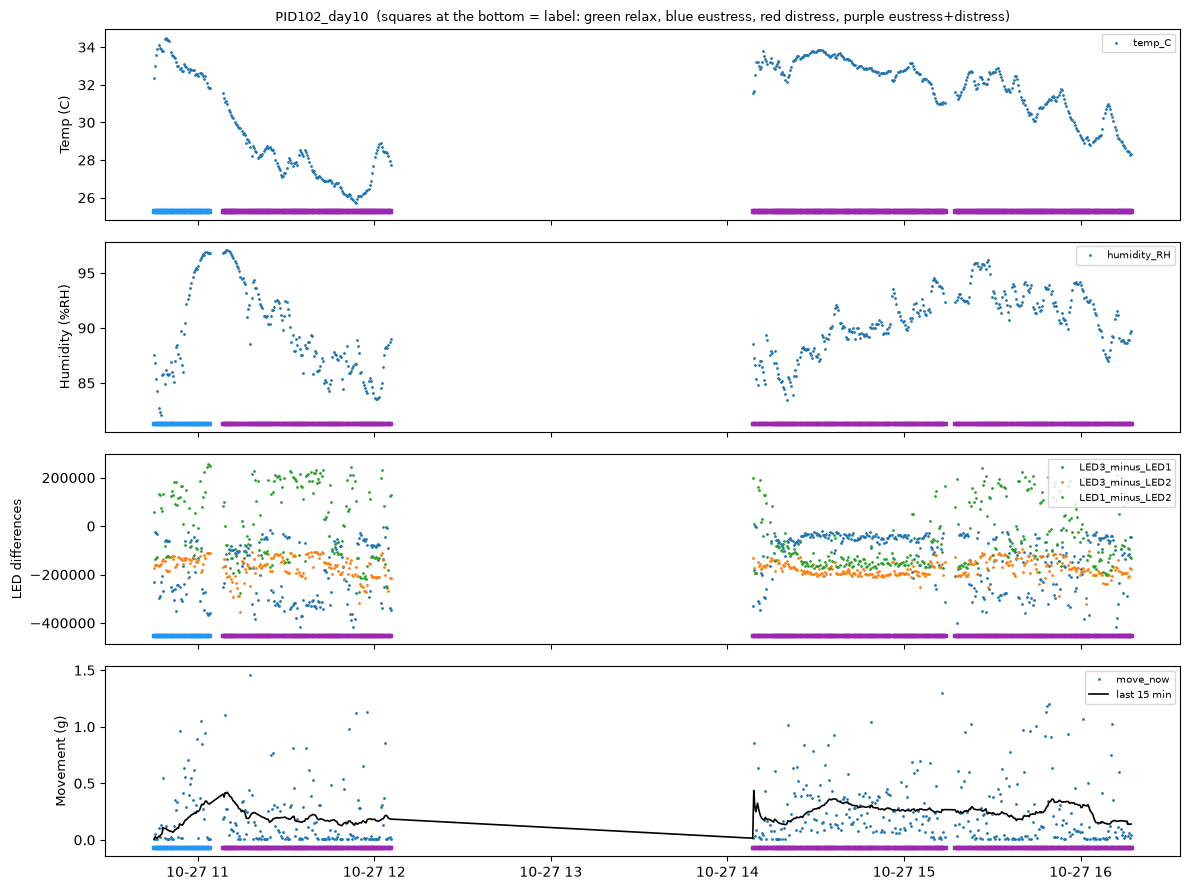

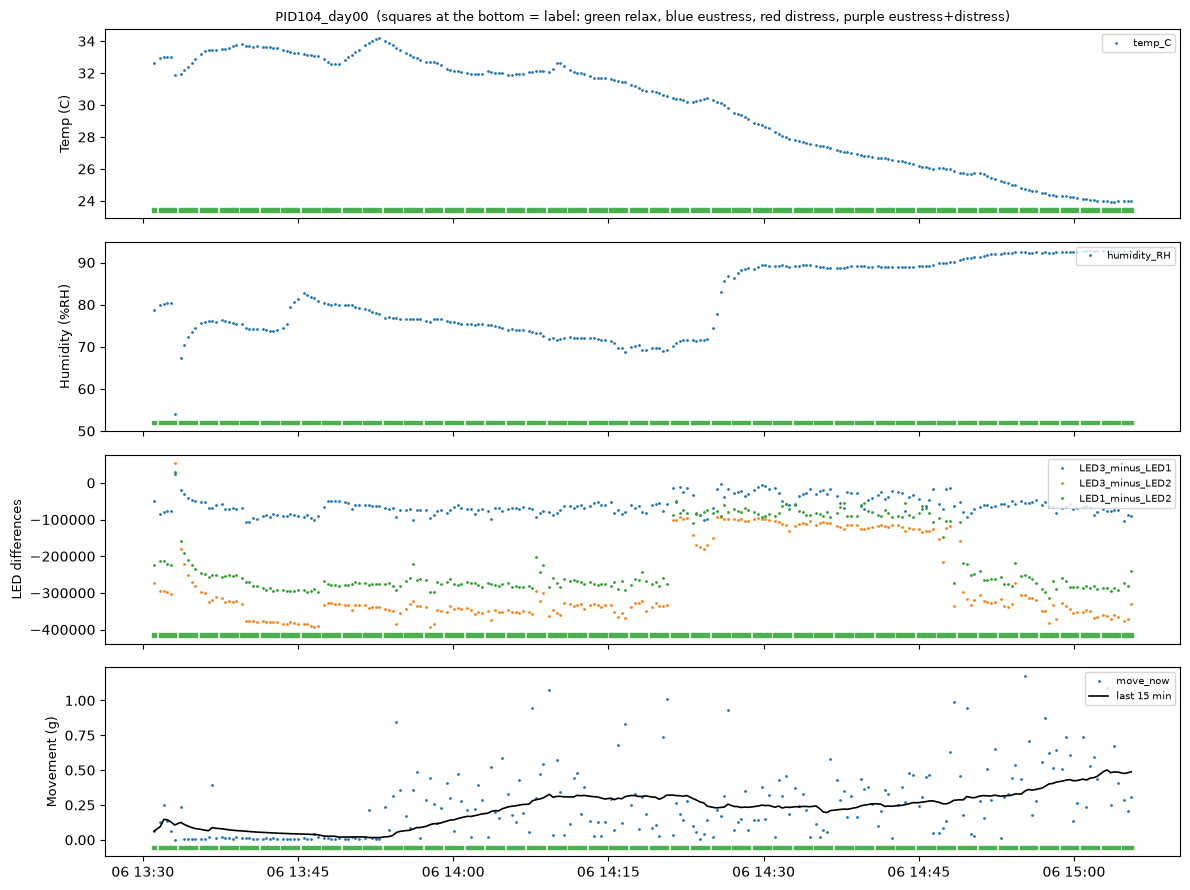

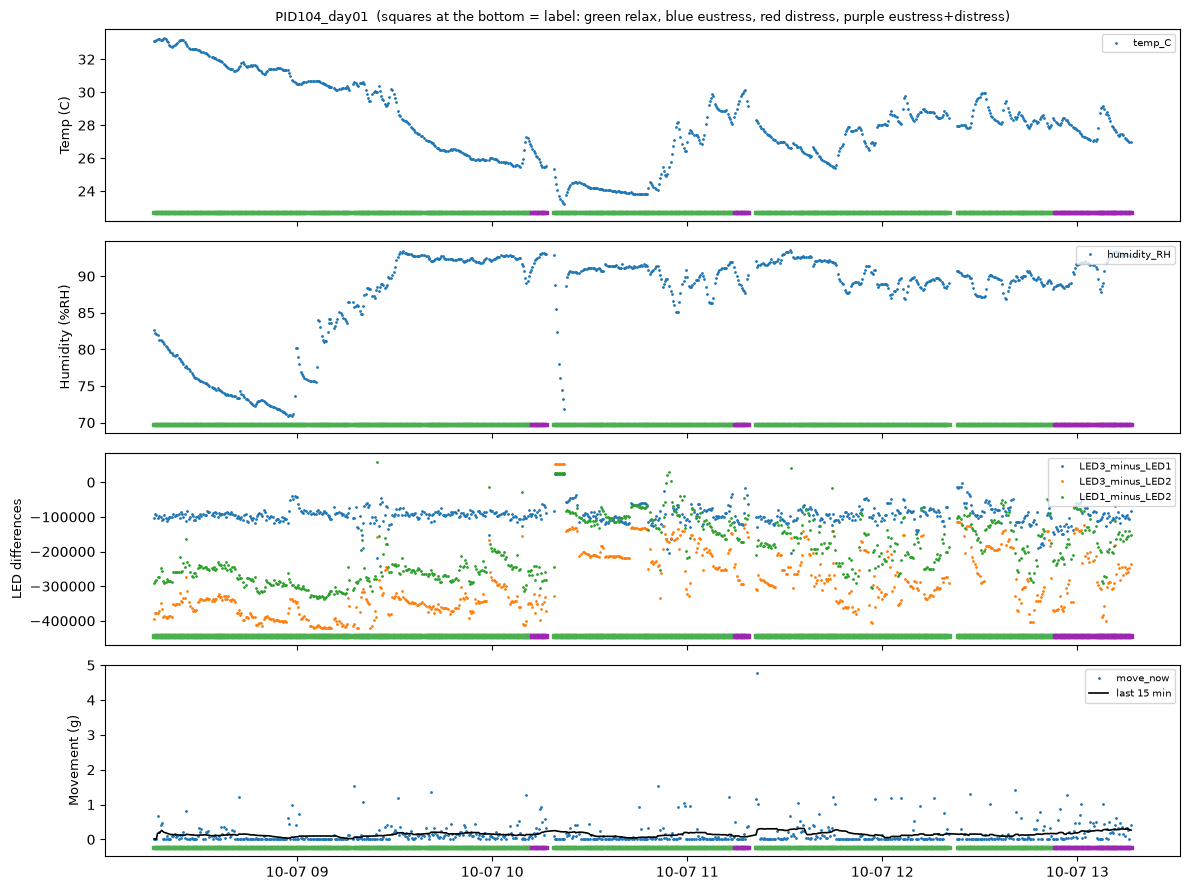

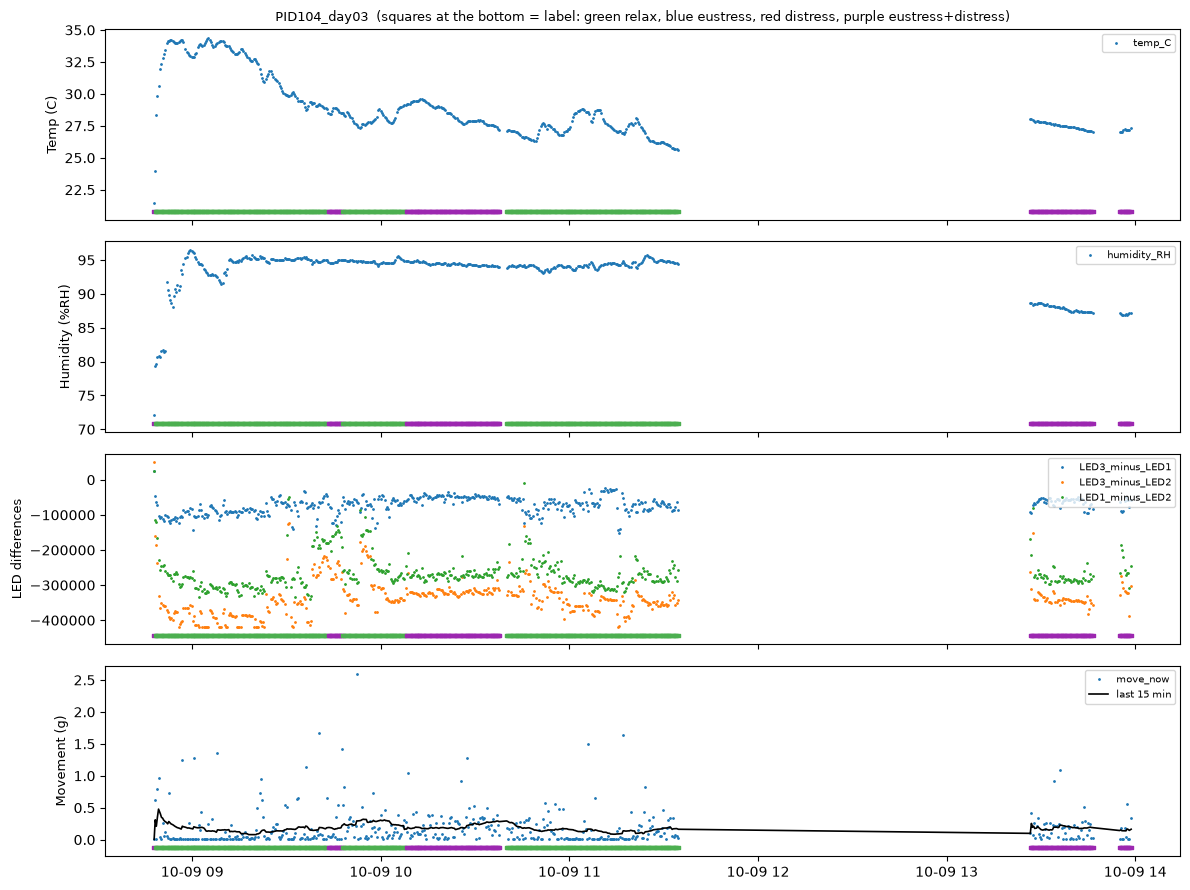

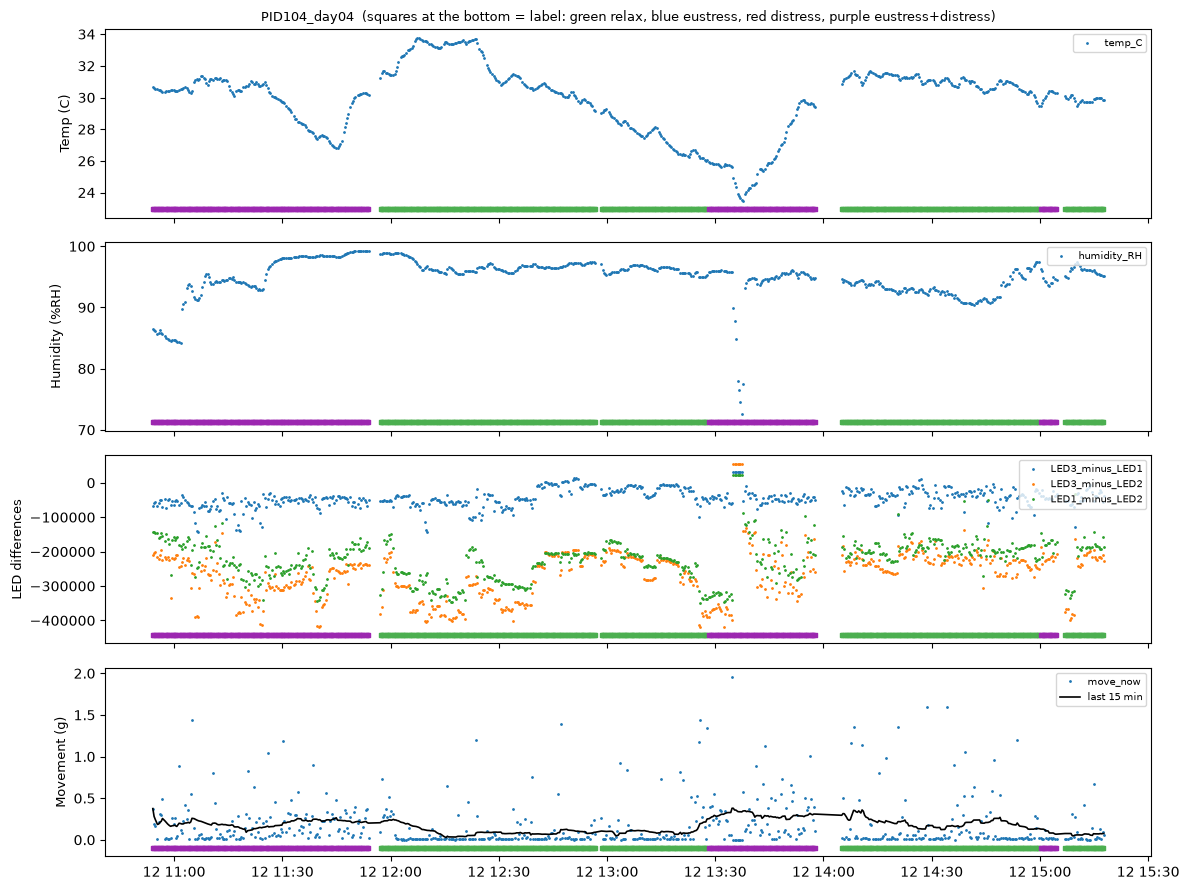

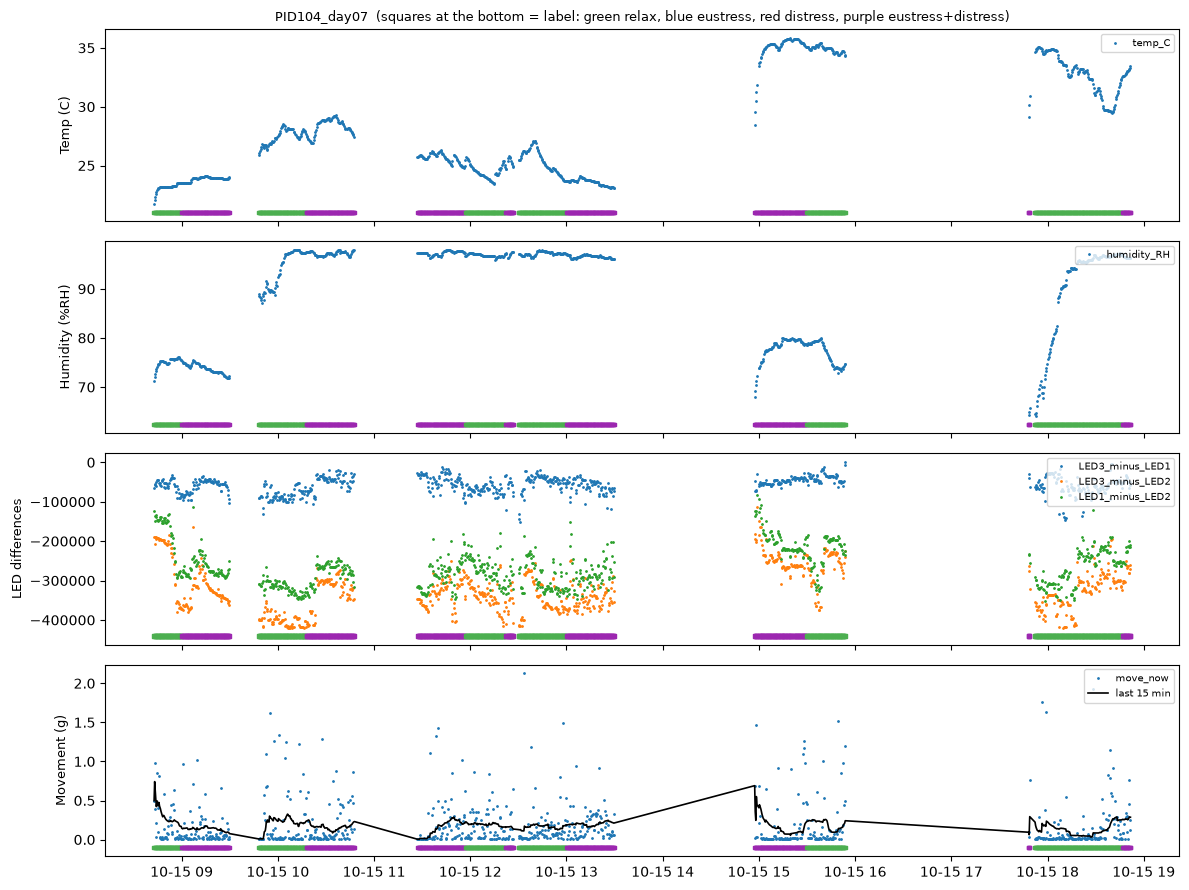

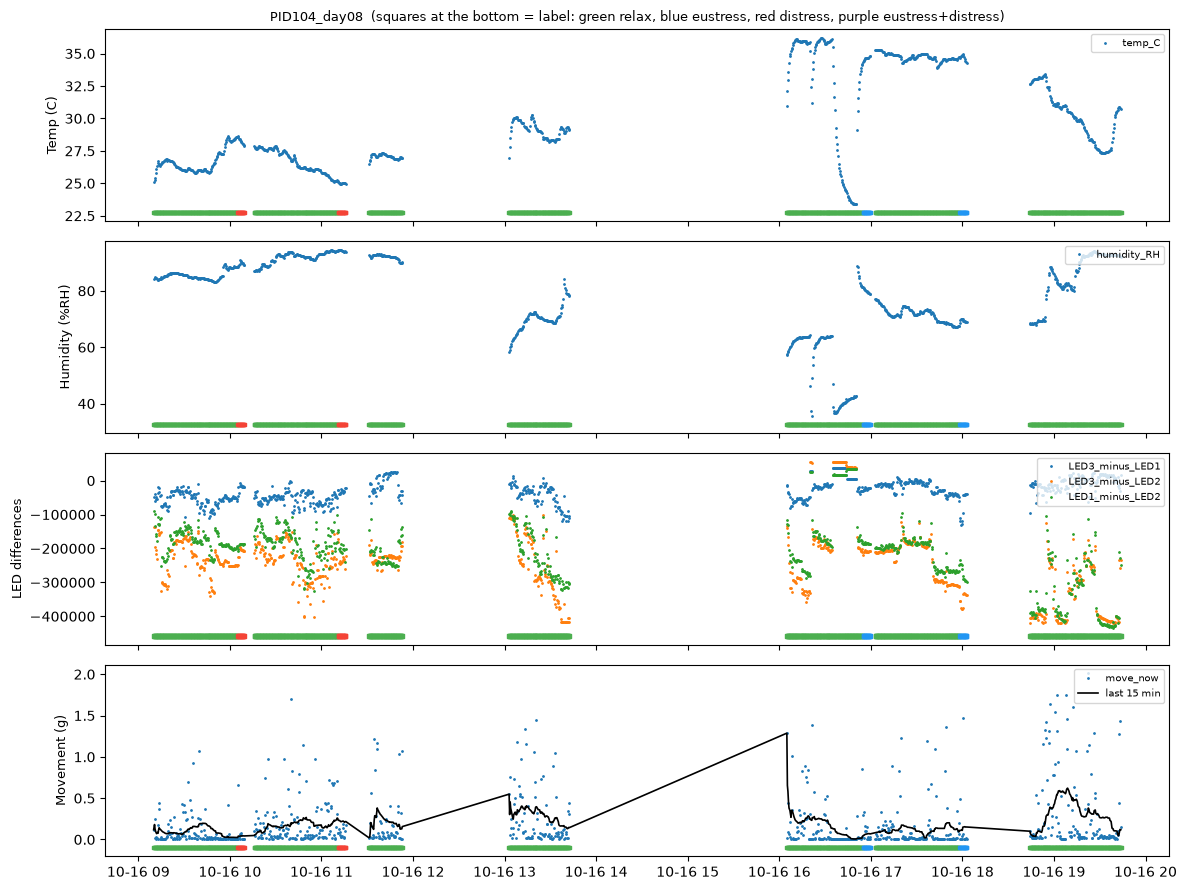

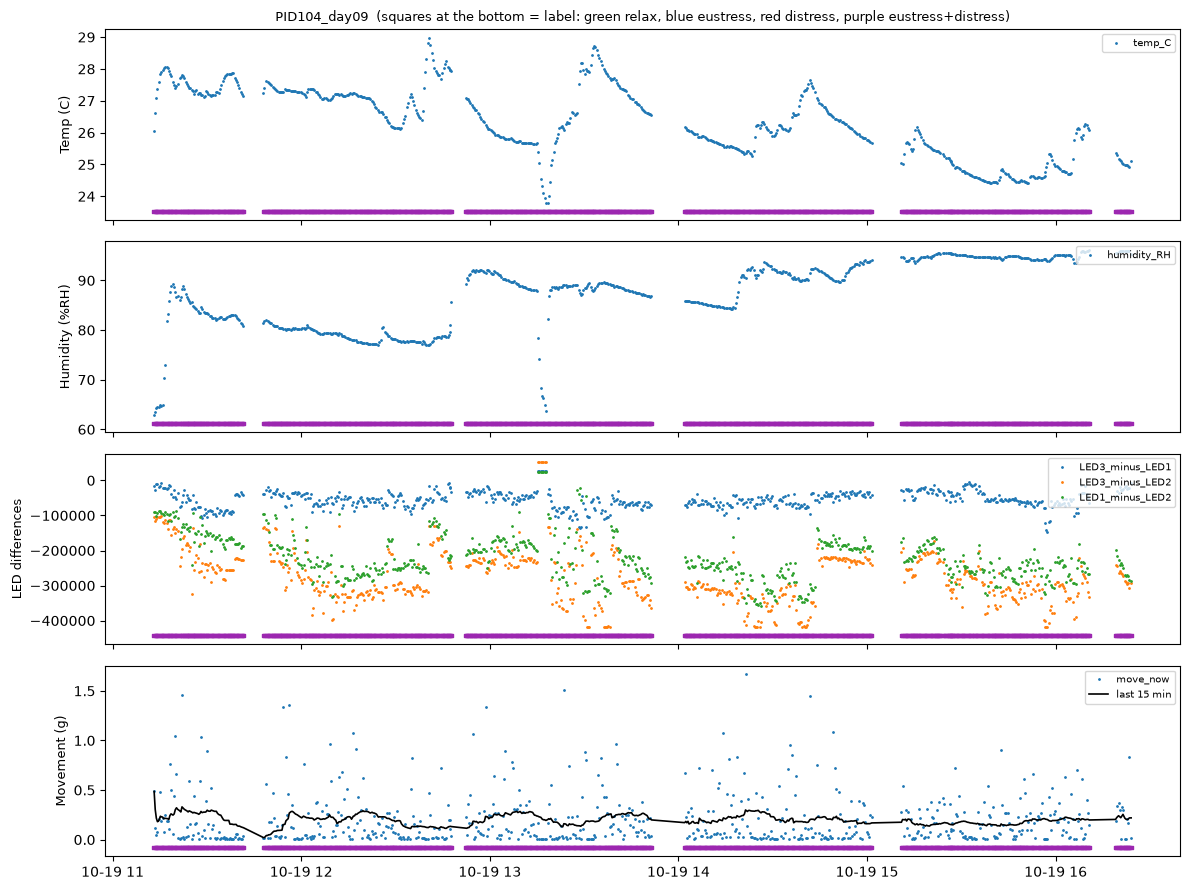

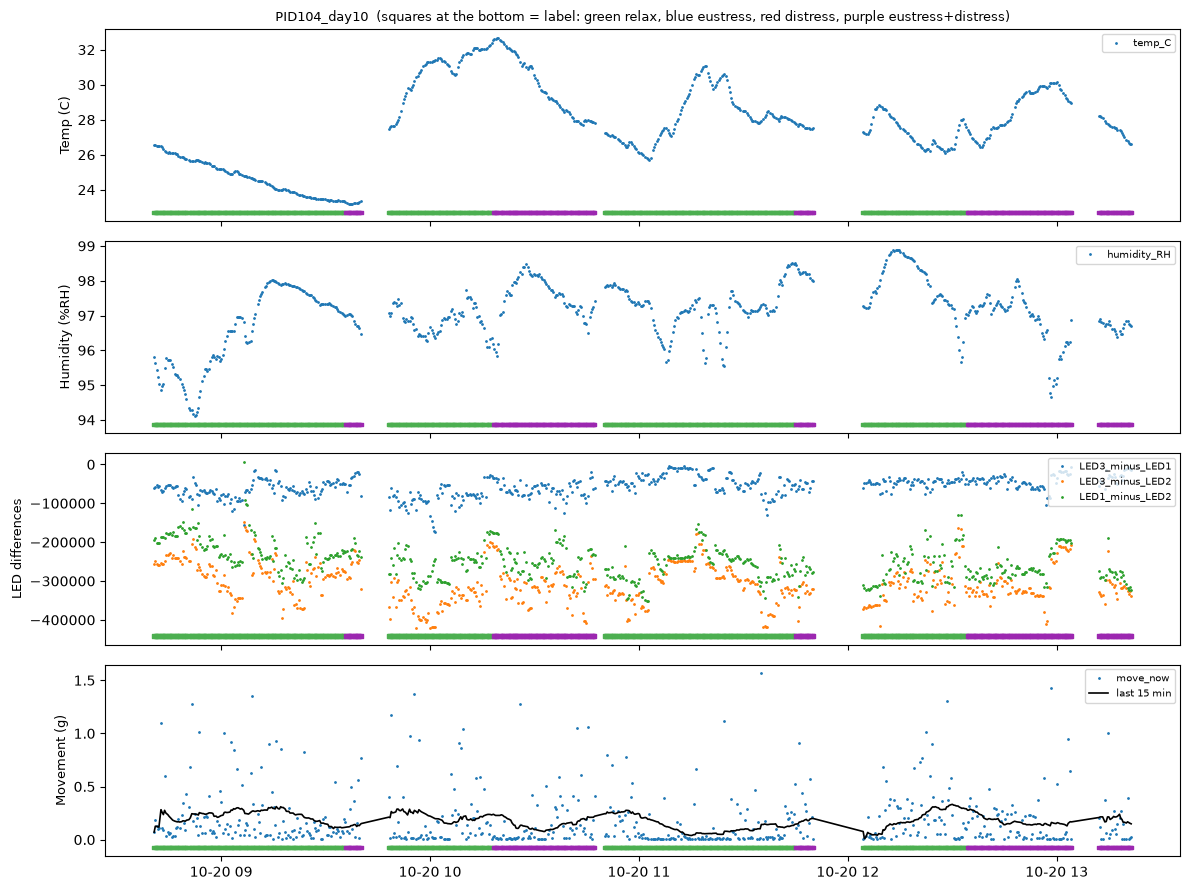

In [5]:
for d, w in df.sort_values("day").groupby("day"):
    plot_day(w, out / "plots" / f"{d}_timeseries.png")

## 4. Correlation with the accelerometer (Spearman)
- **Pooled**: all rings mixed. Can be misleading, because rings differ in both movement and sensor levels.
- **Within-day**: correlation inside each day, median over days. This is the real relationship.

PID101


,rho_move_now,rho_move_5min,rho_move_15min,rho_orient_x,rho_orient_y,rho_orient_z
feature,,,,,,
temp_C,-0.05,-0.14,-0.12,-0.00,-0.02,0.05
humidity_RH,0.00,0.01,0.02,-0.03,0.00,0.15
LED1_mean,0.18,0.12,0.09,-0.12,0.11,0.07
LED2_mean,0.01,-0.00,0.01,0.44,-0.44,0.09
LED3_mean,0.02,0.04,0.01,0.11,-0.04,-0.06
LED3_minus_LED1,-0.18,-0.12,-0.09,0.13,-0.11,-0.07
LED3_minus_LED2,-0.01,0.00,-0.01,-0.44,0.44,-0.09
LED1_minus_LED2,0.08,0.05,0.04,-0.18,0.20,0.02


PID102


,rho_move_now,rho_move_5min,rho_move_15min,rho_orient_x,rho_orient_y,rho_orient_z
feature,,,,,,
temp_C,0.10,0.15,0.18,0.10,-0.03,-0.03
humidity_RH,0.22,0.33,0.35,-0.03,0.01,0.11
LED1_mean,0.07,0.01,0.01,0.13,-0.13,0.18
LED2_mean,-0.05,-0.03,-0.01,0.00,-0.21,0.13
LED3_mean,-0.09,-0.10,-0.13,-0.12,0.11,-0.16
LED3_minus_LED1,-0.07,-0.02,-0.02,-0.14,0.14,-0.19
LED3_minus_LED2,0.05,0.03,0.01,-0.01,0.22,-0.14
LED1_minus_LED2,0.05,-0.02,-0.04,0.09,0.10,-0.05


PID104


,rho_move_now,rho_move_5min,rho_move_15min,rho_orient_x,rho_orient_y,rho_orient_z
feature,,,,,,
temp_C,-0.16,-0.16,-0.20,0.10,-0.17,-0.13
humidity_RH,0.10,0.05,0.04,-0.07,0.01,0.19
LED1_mean,0.02,0.01,-0.03,0.23,-0.10,0.13
LED2_mean,-0.03,-0.02,-0.02,0.00,-0.08,0.06
LED3_mean,0.12,0.11,0.13,0.02,0.10,0.10
LED3_minus_LED1,-0.02,-0.01,0.04,-0.23,0.11,-0.13
LED3_minus_LED2,0.03,0.03,0.02,-0.00,0.09,-0.06
LED1_minus_LED2,0.03,0.03,0.01,0.12,0.05,-0.03


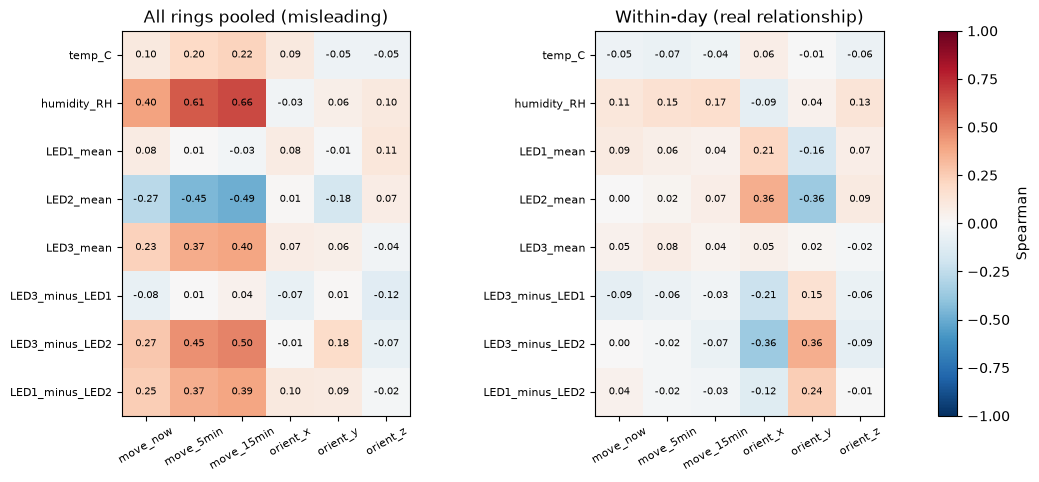

In [6]:
cols = [f"rho_{a}" for a in ACC]
pooled = corr_table(df).set_index("feature")
perring = {p: corr_table(g).set_index("feature") for p, g in df.groupby("PID")}
wd = (pd.concat([corr_table(g).set_index("feature") for _, g in df.groupby("day") if len(g) > 50])
      .groupby(level=0).median().loc[SLOW])
rows = []
for scope, t in [("ALL_pooled", pooled)] + list(perring.items()) + [("within_day_median", wd)]:
    t = t.reset_index(); t.insert(0, "scope", scope); rows.append(t)
pd.concat(rows).round(3).to_csv(out / "correlations_with_accelerometer.csv", index=False)
for p, t in perring.items():
    print(p); display(t[cols].round(2))

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, (t, ttl) in zip(axs, [(pooled, "All rings pooled (misleading)"), (wd, "Within-day (real relationship)")]):
    m = t[cols]; im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(ACC))); ax.set_xticklabels(ACC, rotation=30, fontsize=8)
    ax.set_yticks(range(len(SLOW))); ax.set_yticklabels(SLOW, fontsize=8)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(ttl)
fig.colorbar(im, ax=axs, label="Spearman")
fig.savefig(out / "plots" / "correlation_heatmaps.png", dpi=130, bbox_inches="tight"); plt.show()

## 5. Slow features at low / medium / high movement (per ring)

In [7]:
df["move_level"] = df.groupby("PID").move_now.transform(lambda s: pd.qcut(s, 3, labels=False)).map({0: "low", 1: "medium", 2: "high"})
bm = df.groupby(["PID", "move_level"])[SLOW].median().round(2)
bm.to_csv(out / "slow_features_by_movement_level.csv"); display(bm)

temp_C  humidity_RH  LED1_mean  LED2_mean  LED3_mean  LED3_minus_LED1  LED3_minus_LED2  LED1_minus_LED2
PID    move_level                                                                                                         
PID101 high         31.17       100.69  172440.63  269589.33  108707.68        -63852.93       -161360.11        -97952.97
       low          31.38       100.81  129226.37  274146.89  108597.34        -19830.24       -165346.56       -128810.19
       medium       31.00       100.58  190594.24  255389.79  108486.95        -82237.83       -147244.07        -65431.86
PID102 high         29.92        91.44  190021.68  312359.43  107835.81        -81626.45       -203097.22       -151679.47
       low          28.98        89.61  178174.78  327698.21  108481.39        -68801.98       -217348.00       -159638.84
       medium       29.04        91.22  196839.71  320361.34  107894.51        -88669.77       -210953.79       -149032.50
PID104 high         27.44        92.78  160724.71  405291.09  105254.00        -55011.73       -300031.57       -239803.42
       low          28.80        90.58  161760.08  405767.08  104765.60        -56379.47       -301044.94       -241393.39
       medium       27.58        92.74  159360.20  407237.44  105138.29        -53949.33       -302610.01       -244262.15

## 6. What explains each slow feature (0 to 1)
- `R2_acc_within_day_avg`: explained by movement + orientation inside a day
- `share_ring`, `share_day`: how much it changes between rings / days
- `share_label`: how much it changes with the stress label; `_within_day` after removing day differences

In [8]:
E = []
for f in SLOW:
    resid = df[f] - df.groupby("day")[f].transform("mean")
    E.append({"feature": f,
              "R2_acc_within_day_avg": np.nanmean([r2_from_acc(g, f) for _, g in df.groupby("day")]),
              "share_ring": eta2(df[f], df.PID), "share_day": eta2(df[f], df.day),
              "share_label": eta2(df[f], df.Label), "share_label_within_day": eta2(resid, df.Label)})
E = pd.DataFrame(E).set_index("feature"); E.round(3).to_csv(out / "what_explains_slow_features.csv")
display(E.round(3))

,R2_acc_within_day_avg,share_ring,share_day,share_label,share_label_within_day
feature,,,,,
temp_C,0.226,0.100,0.287,0.058,0.028
humidity_RH,0.202,0.314,0.509,0.054,0.002
LED1_mean,0.169,0.096,0.383,0.024,0.009
LED2_mean,0.211,0.375,0.498,0.061,0.007
LED3_mean,0.155,0.194,0.301,0.082,0.003
LED3_minus_LED1,0.173,0.086,0.388,0.021,0.009
LED3_minus_LED2,0.215,0.401,0.520,0.067,0.008
LED1_minus_LED2,0.188,0.315,0.565,0.075,0.004


## 7. Temperature warm-up within a session

,median temp (C)
min_in_session,
"(-1.0, 5.0]",31.25
"(5.0, 10.0]",32.53
"(10.0, 20.0]",32.60
"(20.0, 40.0]",31.52
"(40.0, 80.0]",30.08
"(80.0, 10000.0]",27.99


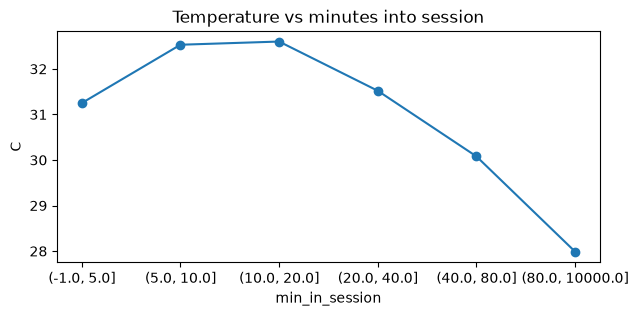

In [9]:
df = df.sort_values(["day", "Session_ID", "time"])
df["min_in_session"] = (df.time - df.groupby(["day", "Session_ID"]).time.transform("min")).dt.total_seconds() / 60
warm = df.groupby(pd.cut(df.min_in_session, [-1, 5, 10, 20, 40, 80, 1e4]), observed=True).temp_C.median().round(2)
display(warm.to_frame("median temp (C)"))
ax = warm.plot(marker="o", figsize=(7, 3), title="Temperature vs minutes into session"); ax.set_ylabel("C"); plt.show()